* * * * * * * * * * *
Master notebook to run every step of the analyses of the Z0 experiment in python.

Authors: Rodrigo Guedes Lang (rodrigo.lang@fau.de), Pedro Batista (pedro.batista@fau.de)

Date: Sep 2024

Based on scripts by Kathrin Valerius and Jannik Hofestaedt from 2011-2013
* * * * * * * * * * *

# Important note:

- At the end of each section, remember to commit your changes (preferrably, but you can commit as many times you want), after you checked out to your group's branch.
- At the end of each day, remember to push your changes to your remote branch with `git push`. **DO NOT PUSH TO THE MAIN  BRANCH** (you should not be able to, but do not try it either way). If you're unsure about which branch you're in currently, run `git status` or `git branch` to check it.

#### Git cheat sheet: https://education.github.com/git-cheat-sheet-education.pdf

In [1]:
from glob import glob
from natsort import natsorted
import uproot
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

In [2]:
from PIL import Image
from IPython.display import display

import ipywidgets as widgets
from ipywidgets import interact

import random

In [3]:
def browse_images(channel):
    images = natsorted(glob(f'../Data/GROPEScreenshots/{channel}/*.png'))
    def view_image(i):
        display(Image.open(images[i]))
    interact(view_image, i=(0,len(images)-1))

def pick_images():
    n = random.sample(range(0,40), k=10)
    images = natsorted(glob(f'../Data/GROPEScreenshots/test/*.png'))
    def view_image(i):
        display(Image.open(images[i]))
    interact(view_image, i=n)
    print(n)

# Part 1 - Qualitative analysis of events

In this part of the experiment, the main idea is to look at a small subset of Monte Carlo (MC) events to build up insight on how events from each channel look like on average. The final good is to come up with some crude cuts to separate the channels.

## Part 1.1 - GROPE event display

### Exercises

- 1.1. For each channel, describe qualitatively the features of its events.

- 1.2. Come up with a 4x4 table describing which variables are important for separating each pair of channels

In [29]:
browse_images("mm")

interactive(children=(IntSlider(value=9, description='i', max=19), Output()), _dom_classes=('widget-interact',…

- 1.3. Now, for 10 randomly selected images, just by looking at the GROPE image, try to evaluate what channel each event originates from (ee, mm, tt or qq).

In [30]:
pick_images()

interactive(children=(Dropdown(description='i', options=(2, 32, 1, 7, 35, 0, 8, 33, 36, 13), value=2), Output(…

[2, 32, 1, 7, 35, 0, 8, 33, 36, 13]


# Part 2 - Quantitative analysis of events

Looking at singular events may help understanding how they look like in the detector. Nevertheless, due to the stochastic nature of the processes involved, each event will look quite differently and we need to look at event distributions.

In the previous part, we have dealt with very few MC events to create a better insight on what their properties and differences are. In this part, we will move on to a much larger set of MC events so that more complete and well-described distributions can be analysed. From here on, information and images of single events will not be used anymore.

## Part 2.1 - Generating histograms

In [83]:
# Example for a single channel
file = uproot.open("../Data/MC/ee.root999., 9")
tree = file['h3']

Ncharged = np.array(tree['Ncharged'].array())
Pcharged = np.array(tree['Pcharged'].array())
E_ecal = np.array(tree['E_ecal'].array())
E_hcal = np.array(tree['E_hcal'].array())
cos_thru = np.array(tree['cos_thru'].array())
cos_thet = np.array(tree['cos_thet'].array())

Each one of the python variable above is `numpy.ndarray`, containing available MC data such as number of charged tracks (e.g. `Ncharged`), or energy deposited in the electromagnetic calorimeter (e.g. `E_ecal`)

In [84]:
print(Ncharged, type(Ncharged))

[2. 2. 0. ... 2. 2. 2.] <class 'numpy.ndarray'>


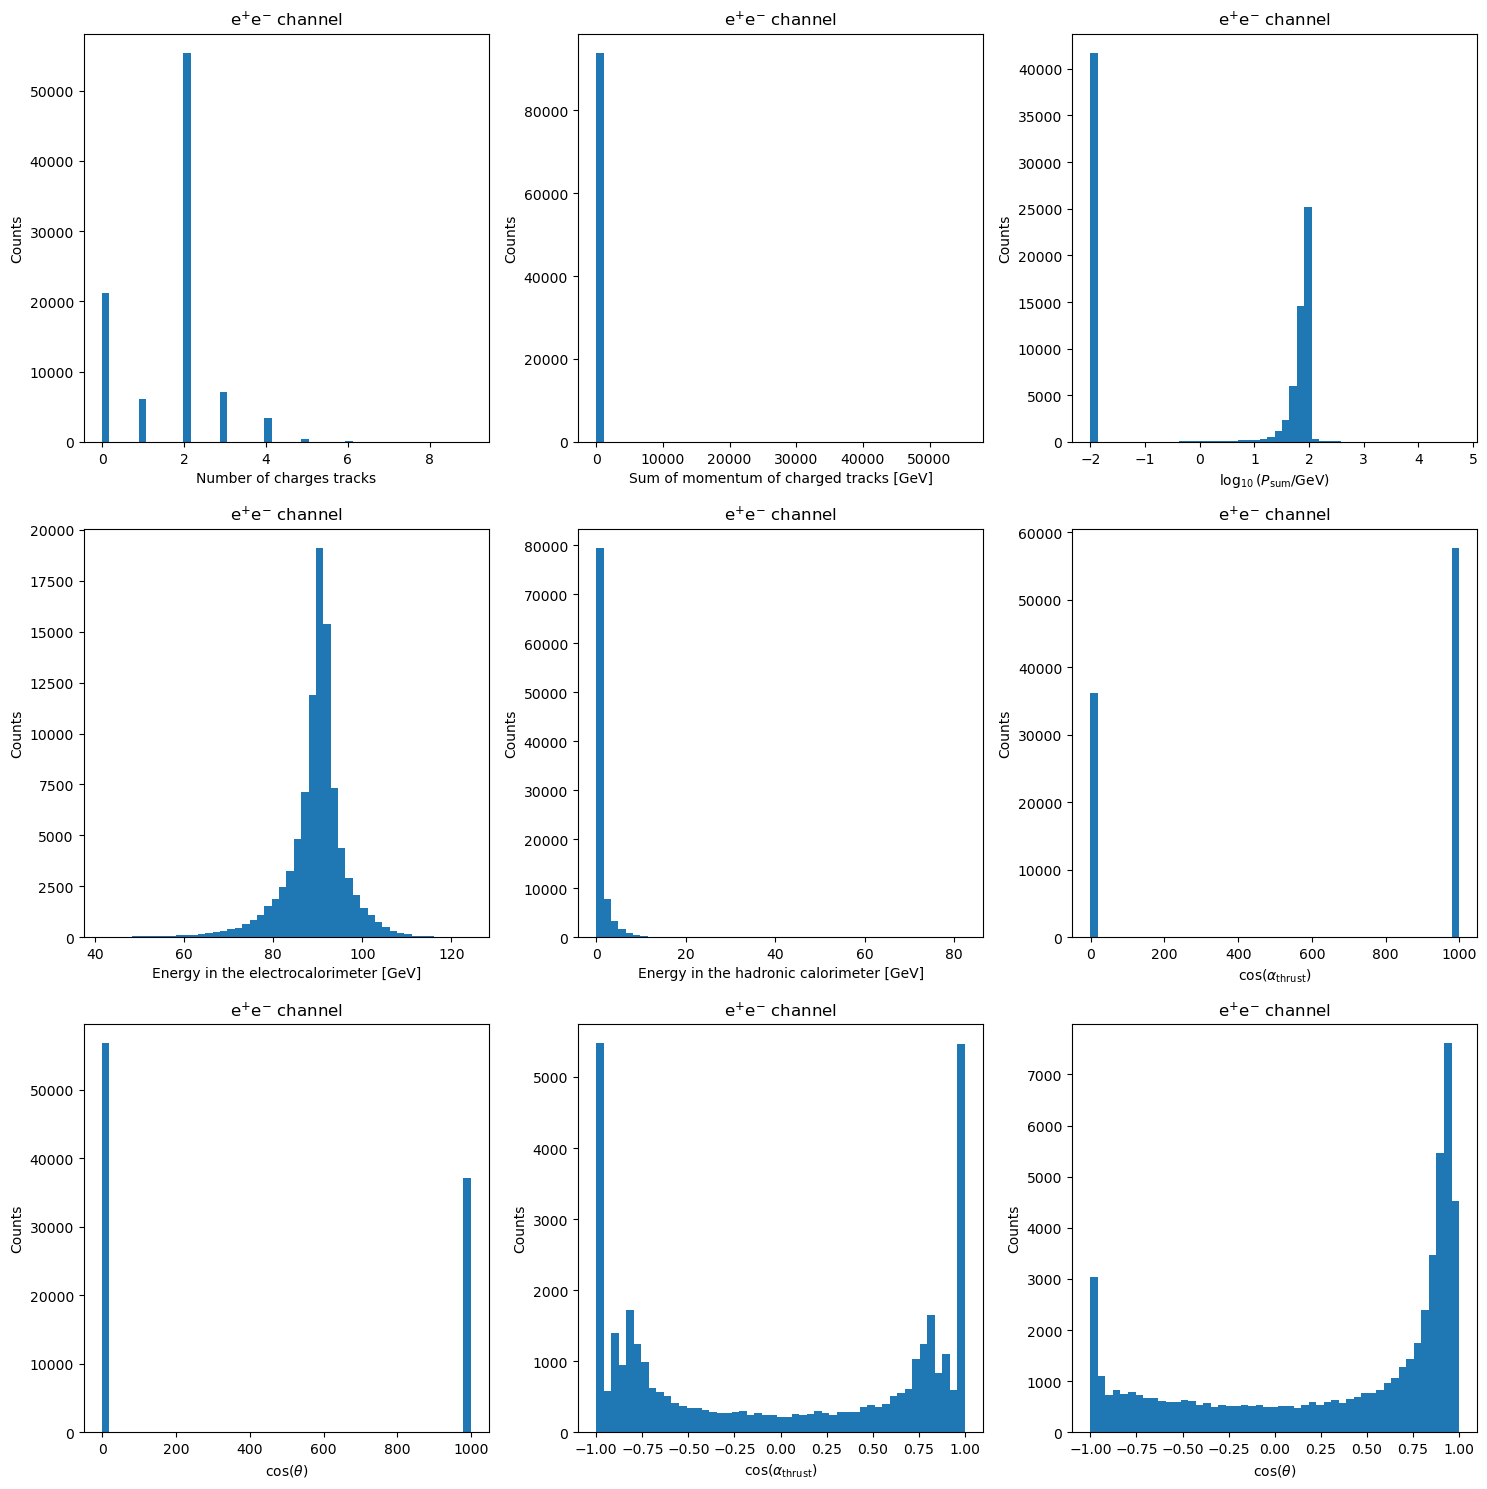

In [90]:
fig, ax = plt.subplots(nrows=3, ncols=3, figsize=(15, 15)) ## Create a grid of figures
## Each axis in ax is accessed via matrix notation, e.g., ax[i,j]

ax[0,0].hist(Ncharged, bins=50)
ax[0,0].set_xlabel("Number of charges tracks")
ax[0,0].set_ylabel("Counts")
ax[0,0].set_title(r"$\rm{e^{+}e^{-}}$ channel")

## If you want to generate just one figure for a quick check, you don't need to create fig and ax instances with plt.subplots()
## Instead, you might want to just use plt.plot() or plt.hist() like this:
"""
plt.hist(Ncharged,bins=50)
plt.xlabel("Number of charges tracks")
plt.ylabel("Counts")
plt.title(r"$\rm{e^{+}e^{-}}$ channel")
"""
##

ax[0,1].hist(Pcharged, bins=50)
ax[0,1].set_xlabel("Sum of momentum of charged tracks [GeV]")
ax[0,1].set_ylabel("Counts")
ax[0,1].set_title(r"$\rm{e^{+}e^{-}}$ channel")

ax[0,2].hist(np.log10(Pcharged+0.01), bins=50)
ax[0,2].set_xlabel(r"$\log_{10} (P_{\rm{sum}} / \rm{GeV})$")
ax[0,2].set_ylabel("Counts")
ax[0,2].set_title(r"$\rm{e^{+}e^{-}}$ channel")

ax[1,0].hist(E_ecal, bins=50)
ax[1,0].set_xlabel("Energy in the electrocalorimeter [GeV]")
ax[1,0].set_ylabel("Counts")
ax[1,0].set_title(r"$\rm{e^{+}e^{-}}$ channel")

ax[1,1].hist(E_hcal, bins=50)
ax[1,1].set_xlabel("Energy in the hadronic calorimeter [GeV]")
ax[1,1].set_ylabel("Counts")
ax[1,1].set_title(r"$\rm{e^{+}e^{-}}$ channel")

ax[1,2].hist(cos_thru, bins=50)
ax[1,2].set_xlabel(r"$\cos(\alpha_{\rm{thrust}})$")
ax[1,2].set_ylabel("Counts")
ax[1,2].set_title(r"$\rm{e^{+}e^{-}}$ channel")

ax[2,0].hist(cos_thet, bins=50)
ax[2,0].set_xlabel(r"$\cos(\theta)$")
ax[2,0].set_ylabel("Counts")
ax[2,0].set_title(r"$\rm{e^{+}e^{-}}$ channel")

ax[2,1].hist(cos_thru, bins=np.linspace(-1,1,50))
ax[2,1].set_xlabel(r"$\cos(\alpha_{\rm{thrust}})$")
ax[2,1].set_ylabel("Counts")
ax[2,1].set_title(r"$\rm{e^{+}e^{-}}$ channel")

ax[2,2].hist(cos_thet, bins=np.linspace(-1,1,50))
ax[2,2].set_xlabel(r"$\cos(\theta)$")
ax[2,2].set_ylabel("Counts")
ax[2,2].set_title(r"$\rm{e^{+}e^{-}}$ channel")
plt.savefig("e*e-_channel_histograms.png")

fig.tight_layout() ## So labels are not clipped
# fig.savefig("../Figures/example.pdf") or plt.savefig(<str /path/to/filename>) to save the figures

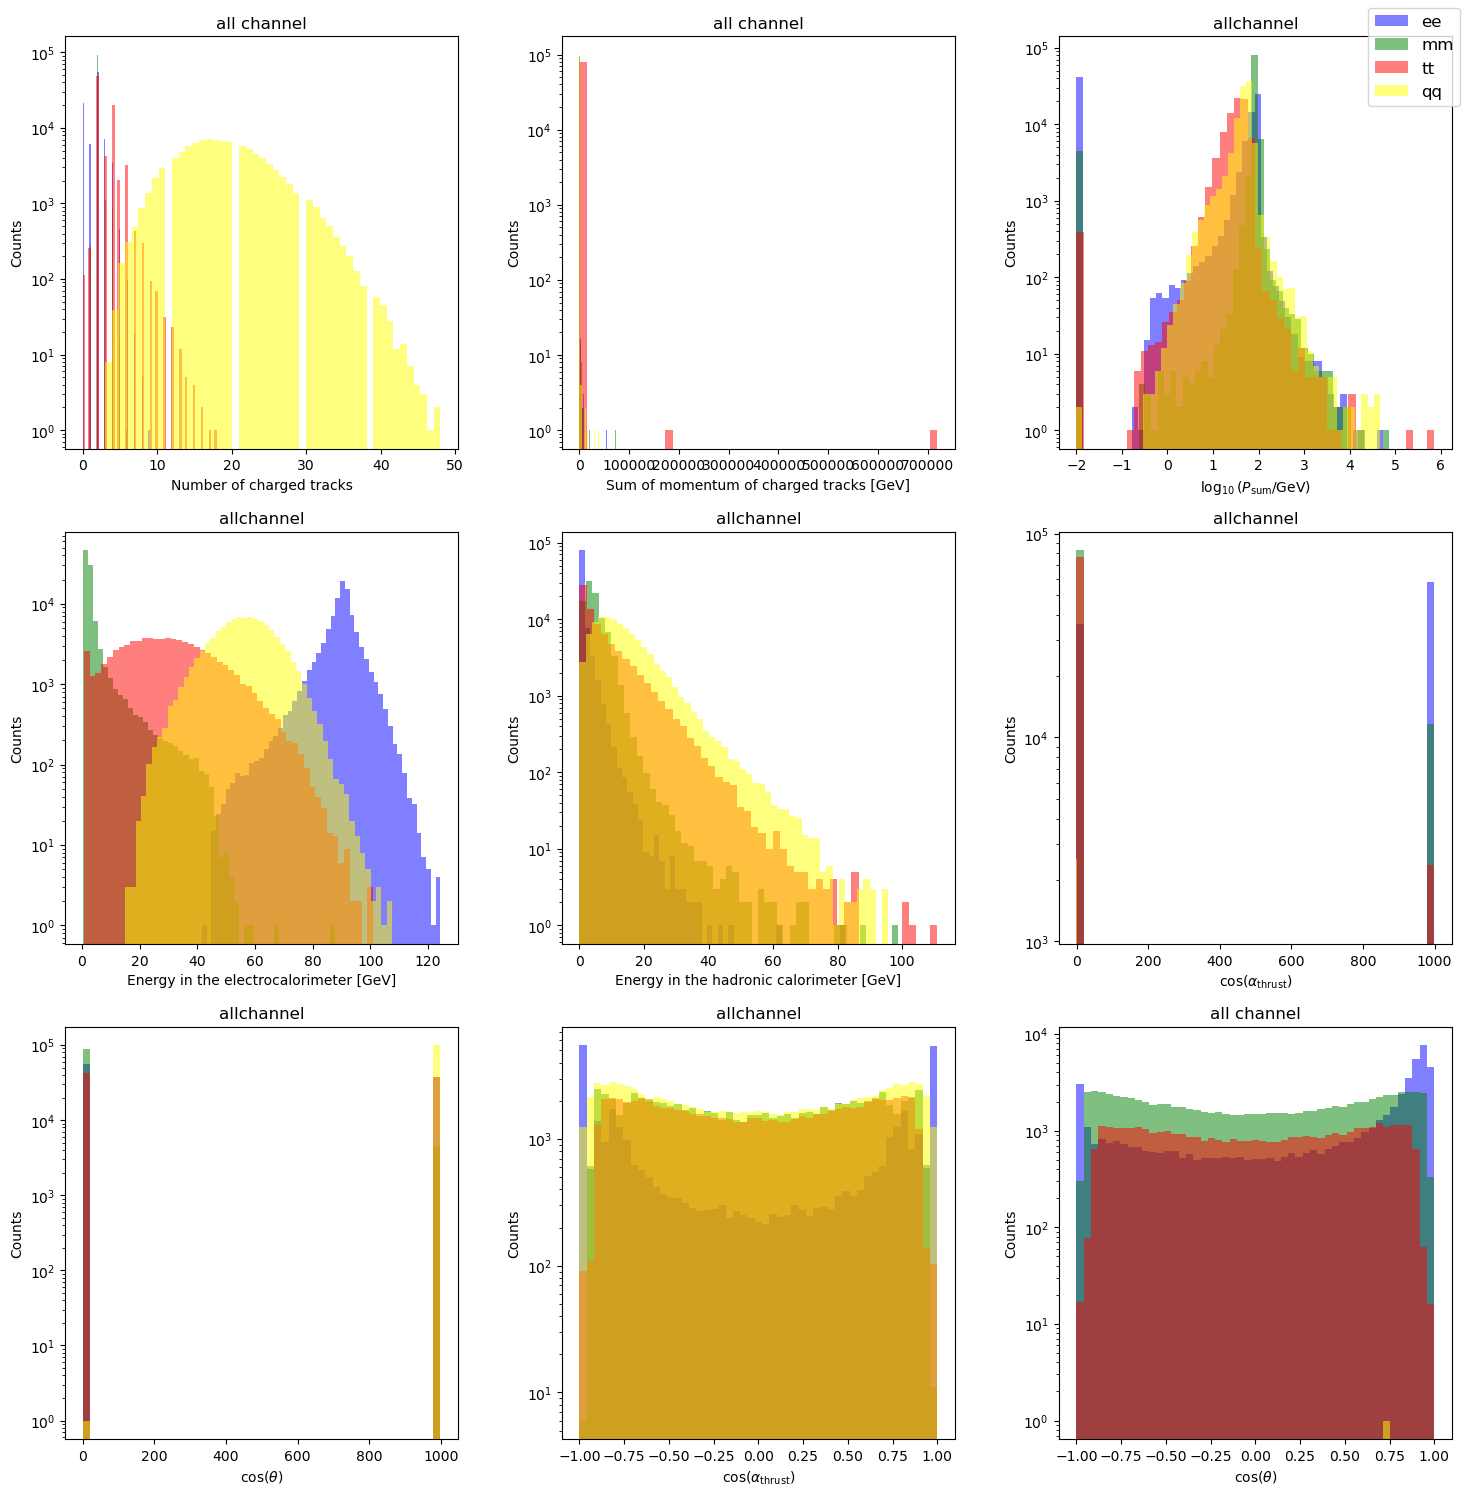

In [213]:
## Create a grid of figures
## Each axis in ax is accessed via matrix notation, e.g., ax[i,j]
file_paths = ["../Data/MC/ee.root", "../Data/MC/mm.root", "../Data/MC/tt.root", "../Data/MC/qq.root"]
colors = ["blue", "green", "red", "yellow", "violet"]
labels = ["ee", "mm", "tt", "qq"]
fig, ax = plt.subplots(nrows=3, ncols=3, figsize=(15, 15))
for i in range(len(file_paths)):
    file = uproot.open(file_paths[i])
    tree = file["h3"]

    Ncharged = np.array(tree['Ncharged'].array())
    Pcharged = np.array(tree['Pcharged'].array())
    E_ecal = np.array(tree['E_ecal'].array())
    E_hcal = np.array(tree['E_hcal'].array())
    cos_thru = np.array(tree['cos_thru'].array())
    cos_thet = np.array(tree['cos_thet'].array())

    ax[0,0].hist(Ncharged, bins=50, color=colors[i], alpha=0.5, label=labels[i])
    ax[0,0].set_xlabel("Number of charged tracks")
    ax[0,0].set_ylabel("Counts")
    ax[0,0].set_title(r"all channel")

    ax[0,1].hist(Pcharged, bins=50, color=colors[i],alpha=0.5)
    ax[0,1].set_xlabel("Sum of momentum of charged tracks [GeV]")
    ax[0,1].set_ylabel("Counts")
    ax[0,1].set_title(r"all channel")

    ax[0,2].hist(np.log10(Pcharged+0.01), bins=50, color=colors[i],alpha=0.5)
    ax[0,2].set_xlabel(r"$\log_{10} (P_{\rm{sum}} / \rm{GeV})$")
    ax[0,2].set_ylabel("Counts")
    ax[0,2].set_title(r"allchannel")

    ax[1,0].hist(E_ecal, bins=50, color=colors[i],alpha=0.5)
    ax[1,0].set_xlabel("Energy in the electrocalorimeter [GeV]")
    ax[1,0].set_ylabel("Counts")
    ax[1,0].set_title(r"allchannel")

    ax[1,1].hist(E_hcal, bins=50, color=colors[i],alpha=0.5)
    ax[1,1].set_xlabel("Energy in the hadronic calorimeter [GeV]")
    ax[1,1].set_ylabel("Counts")
    ax[1,1].set_title(r"allchannel")

    ax[1,2].hist(cos_thru, bins=50, color=colors[i],alpha=0.5)
    ax[1,2].set_xlabel(r"$\cos(\alpha_{\rm{thrust}})$")
    ax[1,2].set_ylabel("Counts")
    ax[1,2].set_title(r"allchannel")

    ax[2,0].hist(cos_thet, bins=50, color=colors[i],alpha=0.5)
    ax[2,0].set_xlabel(r"$\cos(\theta)$")
    ax[2,0].set_ylabel("Counts")
    ax[2,0].set_title(r"allchannel")

    ax[2,1].hist(cos_thru, bins=np.linspace(-1,1,50), color=colors[i],alpha=0.5)
    ax[2,1].set_xlabel(r"$\cos(\alpha_{\rm{thrust}})$")
    ax[2,1].set_ylabel("Counts")
    ax[2,1].set_title(r"allchannel")

    ax[2,2].hist(cos_thet, bins=np.linspace(-1,1,50), color=colors[i],alpha=0.5)
    ax[2,2].set_xlabel(r"$\cos(\theta)$")
    ax[2,2].set_ylabel("Counts")
    ax[2,2].set_title(r"all channel")

    fig.tight_layout()
for a in ax.flatten():
    a.set_yscale("log")
fig.legend(loc="upper right", fontsize=12)
plt.savefig ("all_channel_histograms.png")
plt.show()

    ## So labels are not clipped
# fig.savefig("../Figures/example.pdf") or plt.savefig(<str /path/to/filename>) to save

In [ ]:
mask = (mask_safe) & (Ncharged > 1) & (Ncharged < 4) & (cos_thru > -0.7) & (E_ecal < 100) # completely random cuts, just to show the syntax needed!
mask2 = (Ncharged2 < 4) & (E_ecal2 < 20) & (E_hcal2 <13) & (np.log10(Pcharged2 +0.01) <2) & (np.log10(Pcharged2 +0.01) >1.5)# completely random cuts, just to show the syntax needed!
mask3 = (Ncharged3 < 7) & (Ncharged3 > 2)&(E_ecal3 < 40) & (E_hcal3 <14)# & (np.log10(Pcharged3+0.01) <2) & (np.log10(Pcharged3+0.01) >1)

In [74]:

logP = np.log10(np.maximum(Pcharged, 1e-6) * 0.01)

masks = [

    # ee-like (low tracks, high ECAL)
    (Ncharged > 0) & (Ncharged < 5) &
    (E_ecal > 60) & (E_ecal < 100) &
    (E_hcal < 6) &
    (logP > 1) & (logP < 2.3),

    # mm-like (clean, low energy)
    (Ncharged >= 2) & (Ncharged < 4) &
    (E_ecal < 25) &
    (E_hcal < 10) &
    (logP > 1) & (logP < 2.3),

    # tt-like (intermediate)
    (Ncharged >= 2) & (Ncharged < 10) &
    (E_ecal < 100) &
    (E_hcal < 20) &
    (logP > 1) & (logP < 2),

    # qq-like (hadronic jets)
    (Ncharged >= 7) & (Ncharged < 80) &
    (E_ecal > 20) & (E_ecal < 90) &
    (E_hcal < 25) &
    (logP < 2)
]


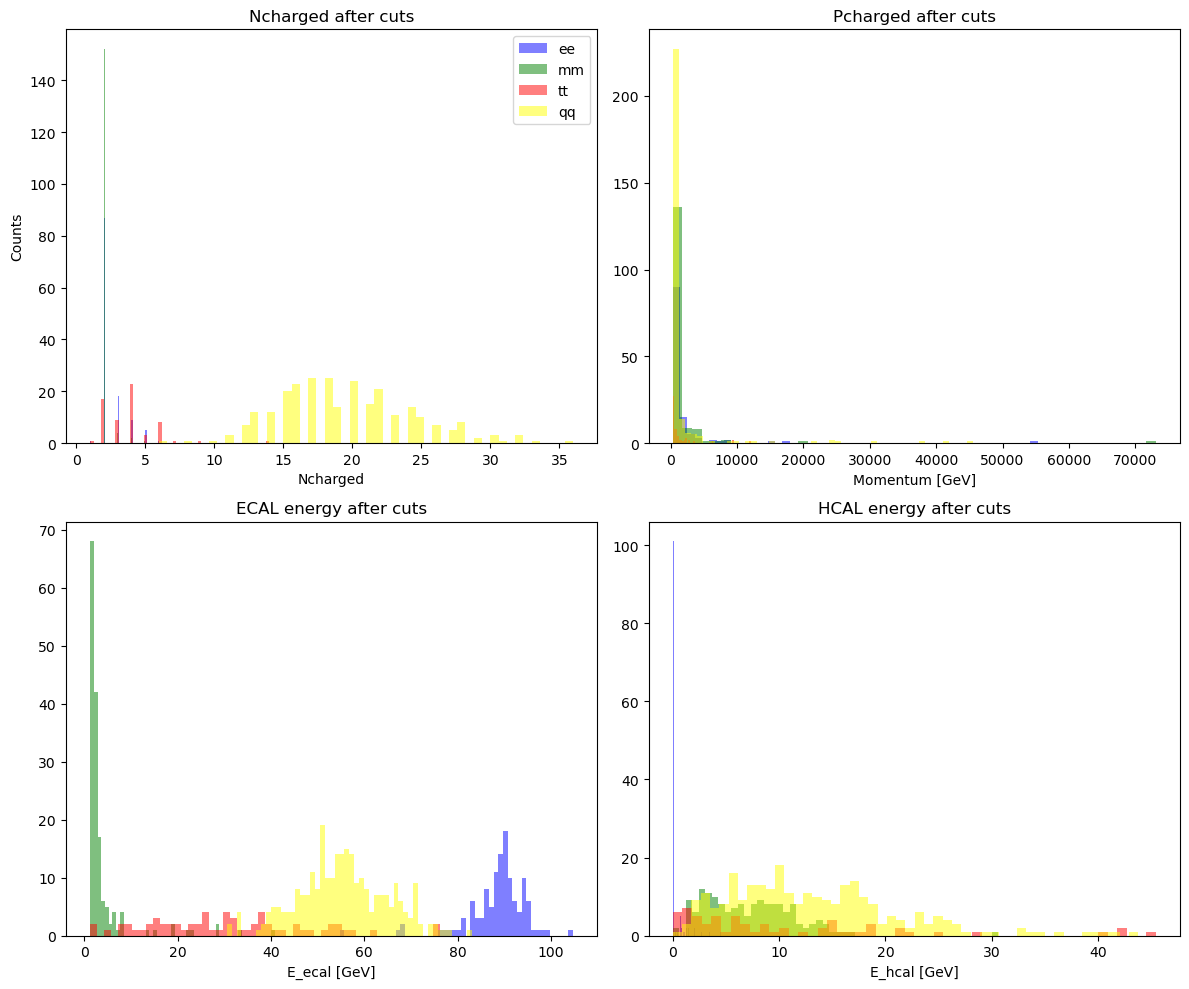

In [100]:

colors = ["blue", "green", "red", "yellow", "violet"]
labels = ["ee", "mm", "tt", "qq"]

# Storage for cut samples

Ncharged_cut = []
Pcharged_cut = []
E_ecal_cut = []
E_hcal_cut = []


# Loop over files

for i, path in enumerate(file_paths):

    file = uproot.open(path)
    tree = file["h3"]

    Ncharged = np.array(tree["Ncharged"].array())
    Pcharged = np.array(tree["Pcharged"].array())
    E_ecal = np.array(tree["E_ecal"].array())
    E_hcal = np.array(tree["E_hcal"].array())

  
    # Safe log momentum (NO warnings)

    logP = np.log10(np.maximum(Pcharged, 1e-6) * 0.01)

    # CUTS (example physics selection)

    mask = (

        (Ncharged > 0) & (Ncharged < 80) &

        (E_ecal >= 0) &
        (E_hcal >= 0) &

        (logP > 0.5) & (logP < 3.0)
    )

  
    # Apply cutsfig, ax = plt.subplots(nrows=3, ncols=3, figsize=(15, 15)) ## Create a grid of figures
## Each axis in ax is accessed via matrix notation, e.g., ax[i,j]

ax[0,0].hist((Ncharged1), bins=50, color=('black'), label=('ee'),histtype='step')
ax[0,0].hist(Ncharged1[mask1], bins=50, color='black', linestyle='--', label='Cuts', histtype='step')
ax[0,0].set_xlabel("Number of charges tracks")
ax[0,0].set_ylabel("Counts")
ax[0,0].legend()



ax[0,1].hist((E_ecal1), bins=50, color=('black'), label=('ee'),histtype='step')
ax[0,1].hist(E_ecal1[mask1], bins=50, color='black', linestyle='--', label='Cuts', histtype='step')
ax[0,1].set_xlabel("Energy in the electrocalorimeter [GeV]")
ax[0,1].set_ylabel("Counts")
#ax[1,0].set_title(r"$\rm{e^{+}e^{-}}$ channel")
ax[0,1].legend()

ax[1,1].hist((E_hcal1), bins=50,color=('black'), label=('ee'),histtype='step')
ax[1,1].hist(E_hcal1[mask1], bins=50, color='black', linestyle='--', label='Cuts', histtype='step')
ax[1,1].set_xlabel("Energy in the hadronic calorimeter [GeV]")
ax[1,1].set_ylabel("Counts")
#ax[1,1].set_title(r"$\rm{e^{+}e^{-}}$ channel")
ax[1,1].legend()
ax[1,1].set_xlim(0,40)

ax[2,2].hist(cos_thet1, bins=np.linspace(-1,1,50),color=('black'), label=('ee'),histtype='step')
ax[2,1].hist(cos_thet[mask1], bins=np.linspace(-1,1,50), color='black', linestyle='--', label='Cuts', histtype='step')
ax[2,2].set_xlabel(r"$\cos(\theta)$")
ax[2,2].set_ylabel("Counts")
#ax[2,2].set_title(r"$\rm{e^{+}e^{-}}$ channel")
ax[2,2].legend()

    Ncharged_cut.append(Ncharged[mask])
    Pcharged_cut.append(Pcharged[mask])
    E_ecal_cut.append(E_ecal[mask])
    E_hcal_cut.append(E_hcal[mask])

# NEW HISTOGRAMS (AFTER CUTS)
78126/100078126/1000
fig, ax = plt.subplots(2, 2, figsize=(12, 10))

# Ncharged
for i in range(4):
    ax[0,0].hist(Ncharged_cut[i], bins=50, alpha=0.5, color=colors[i], label=labels[i])
ax[0,0].set_title("Ncharged after cuts")78126/1000
ax[0,0].set_xlabel("Ncharged")
ax[0,0].set_ylabel("Counts")
ax[0,0].legend()

# Momentum
for i in range(4):
    ax[0,1].hist(Pcharged_cut[i], bins=50, alpha=0.5, color=colors[i])
ax[0,1].set_title("Pcharged after cuts")78126/1000
ax[0,1].set_xlabel("Momentum [GeV]")

# ECAL
for i in range(4):
    ax[1,0].hist(E_ecal_cut[i], bins=50, alpha=0.5, color=colors[i])
ax[1,0].set_title("ECAL energy after cuts")
ax[1,0].set_xlabel("E_ecal [GeV]")

# HCAL
for i in range(4):
    ax[1,1].hist(E_hcal_cut[i], bins=50, alpha=0.5, color=colors[i])
ax[1,1].set_title("HCAL energy after cuts")
ax[1,1].set_xlabel("E_hcal [GeV]")
plt.savefig ("New Histogram after cut before t and s")
plt.tight_layout()
plt.show()

### Questions

Three plots were "redefined".

1. For $P_{\rm{sum}}$, we used log10 (and had to add 0.01). Why?
2. For the angles, we need to constrain to the physical values, i.e., $-1 < \cos(\theta) < 1$. What happened to the events with unphysical angles?

### Exercises

2.1.0. Every plot in this protocol/example notebook has been plotted with the standard style options. Are these the best options in general? For each case? Do you think you can come up with better looking/easier to read plots?

2.1.1. Obtain the same histograms for the other three channels (the input root files are located in the same folder and can be accessed the same way).

2.1.2. Come up with a nice way to show the comparison between the four channels

## Part 2.2 - Separating s-t channels

For $\rm{e^{+}e^{-}}$ channel, not only annihiliation processes (s-channel) are present, but also scattering processes (t-channel). Nevertheless, the Z0 boson can only be produced in the first one and, thus, only those events contribute to the decay width. For that reason, those events must also be selected out.

The two channels differ on their angular distribution:

$\frac{d\sigma}{d\Omega} \alpha \left\{\begin{array}{@{}lr@{}}
        1+\cos^2(\theta), & \text{s-channel}\\
        (1-\cos \theta)^{-2}, & \text{t-channel}\\
        \end{array}\right.$

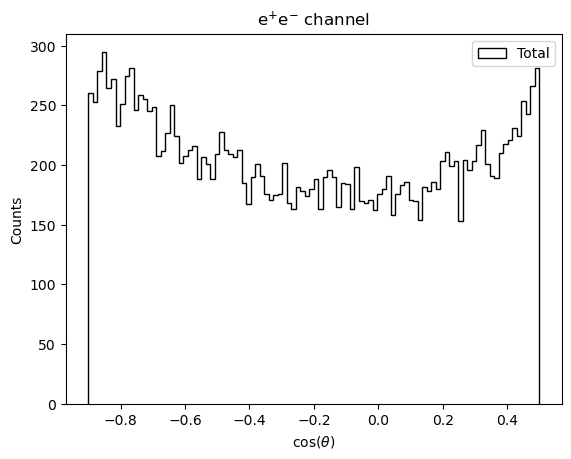

<Figure size 640x480 with 0 Axes>

In [228]:
file = uproot.open("../Data/MC/ee.root")
tree = file['h3']

cos_thet = np.array(tree['cos_thet'].array())

# A first safe cos_theta cut must be applied

mask_safe = (cos_thet>-0.9) & (cos_thet<0.5)

data_hist = plt.hist(cos_thet[mask_safe],bins=np.linspace(-0.9,0.5,101),color='black',label='Total',histtype='step')
plt.xlabel(r"$\cos(\theta)$")
plt.ylabel("Counts")
plt.title(r"$\rm{e^{+}e^{-}}$ channel")
plt.legend()
plt.show()
plt.savefig ("first safe cos cut.png")

We now define a fit function of the type:

$a (1+\cos^2(\theta)) + b (1-\cos \theta)^2$

where $a$ and $b$ are free parameters

In [229]:
def fitFunction(x,a,b):
    first_term = a * (1 + x**2)
    second_term = b * 1 / (1 - x)**2
    result = first_term + second_term
    return result

In [232]:
## Fit and define arrays
popt, pcov = curve_fit(fitFunction, data_hist[1][:-1] + (data_hist[1][1] - data_hist[1][0])/2., data_hist[0])
print("----------------------------------------------------")
print("Fitted parameters:")
print(f"a = {popt[0]} +- { np.sqrt(np.diag(pcov))[0] }")
print(f"b = {popt[1]} +- { np.sqrt(np.diag(pcov))[1] }")
print("----------------------------------------------------")

cos_theta = np.linspace(-0.9, 0.5, 101)

s_counts = popt[0] * (1 + cos_theta**2)
s_upper_bound = (popt[0] + np.sqrt(np.diag(pcov))[0]) * (1 + cos_theta**2) 
s_lower_bound = (popt[0] - np.sqrt(np.diag(pcov))[0]) * (1 + cos_theta**2)

t_counts = popt[1] * 1 / (1 - cos_theta)**2
t_upper_bound = (popt[1] + np.sqrt(np.diag(pcov))[1]) * 1 / (1 - cos_theta)**2
t_lower_bound = (popt[1] - np.sqrt(np.diag(pcov))[1]) * 1 / (1 - cos_theta)**2
fracSChannel= np.sum(s_counts) / (np.sum(s_counts) + np.sum(t_counts))



----------------------------------------------------
Fitted parameters:
a = 156.06058080097526 +- 1.7458652099431065
b = 16.390767619968333 +- 1.561544604844964
----------------------------------------------------


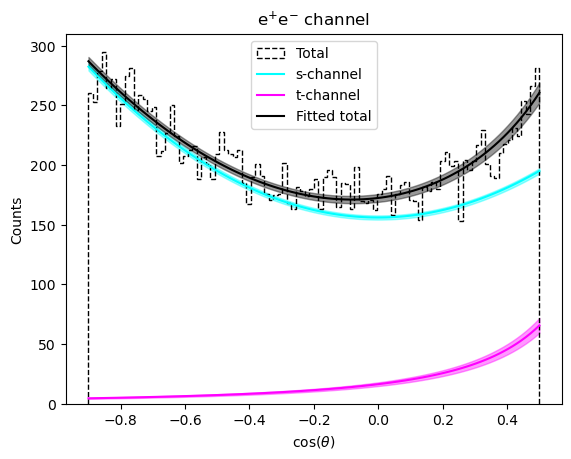

<Figure size 640x480 with 0 Axes>

In [104]:
## Now plot everything:
plt.hist(cos_thet[mask_safe], bins=cos_theta, color='black', label='Total', histtype='step', linestyle='--')

plt.plot(cos_theta, s_counts, label='s-channel',color='cyan')
plt.fill_between(cos_theta, s_lower_bound, s_upper_bound, alpha=0.4, color='cyan')

plt.plot(cos_theta, t_counts, label='t-channel', color='magenta')
plt.fill_between(cos_theta, t_lower_bound, t_upper_bound, alpha=0.4, color='magenta')

plt.plot(cos_theta, s_counts + t_counts, color='black', label='Fitted total')
plt.fill_between(cos_theta, s_lower_bound + t_lower_bound, s_upper_bound + t_upper_bound, alpha=0.4, color='black')

plt.xlabel(r"$\cos(\theta)$")
plt.ylabel("Counts")
plt.title(r"$\rm{e^{+}e^{-}}$ channel")
plt.legend()
plt.show()
plt.savefig ("first safe cos cut with fit.png")

### Exercises

Using the results of the fit:

2.2.1. Calculate the fraction of s-channel events in the region $\cos \theta \in [-0.9,0.5]$

2.2.2. Calculate the total number of s-channel events in $\cos \theta \in [-1,1]$

In [233]:
import numpy as np
from scipy.integrate import quad

# Define the function
def f(x, a, b):
    return a * (1 + x**2) + b * 1/(1 - x)**2

def g(x, a, b):
    return a * (1 + x**2)

# Parameters from fitting
a = 156.0605806321217  # obtained from fitting
b =  16.390767821098247 # obtained from fitting

# Integration limits
lower_limit_1 = -0.9
upper_limit_1 = 0.5
lower_limit_2 = -1
upper_limit_2 =1

# Integrate for both ranges
integral_range_1, _ = quad(g, lower_limit_1, upper_limit_1, args=(a, b))
integral_range_1_1, _ = quad(f, lower_limit_1, upper_limit_1, args=(a, b))
integral_range_2, _ = quad(g, lower_limit_2, upper_limit_2, args=(a, b))

# Calculate fraction and total s-channel events
fraction_s_channel = integral_range_1 / integral_range_1_1

print("Fraction of s-channel events:", fraction_s_channel)
print("Total s-channel events:", integral_range_2)

Fraction of s-channel events: 0.9158558990254517
Total s-channel events: 416.1615483523246


In [234]:
import numpy as np
from scipy.integrate import quad

# Define the function
def f(x, a, b):
    return a * (1 + x**2) + b * 1/(1 - x)**2

def g(x, a, b):
    return a * (1 + x**2)

# Parameters from fitting
a = 156.0605806321217  # obtained from fitting
b =  16.390767821098247 # obtained from fitting

# Integration limits
lower_limit_1 = -0.9
upper_limit_1 = 0.5
lower_limit_2 = -1
upper_limit_2 =1

# Integrate for both ranges
integral_range_1, _ = quad(g, lower_limit_1, upper_limit_1, args=(a, b))
integral_range_1_1, _ = quad(f, lower_limit_1, upper_limit_1, args=(a, b))
integral_range_2, _ = quad(g, lower_limit_2, upper_limit_2, args=(a, b))

# Calculate fraction and total s-channel events
fraction_s_channel = integral_range_1 / integral_range_1_1

# Define a new function for g/f
def g_over_f(x, a, b):
    return g(x, a, b) / f(x, a, b)

# Calculate the integrals for the correction factor
int1, _ = quad(g_over_f, lower_limit_2, upper_limit_2, args=(a, b))
int2, _ = quad(g_over_f, lower_limit_1, upper_limit_1, args=(a, b))

# Calculate the correction factor
correction_factor = int1 / int2


print("Fraction of s-channel events:", fraction_s_channel)
print("Total s-channel events:", integral_range_2)
print("correction factor", int1/int2)



counts=len(cos_thet[mask_safe])
print(counts)

totalcounts=counts*correction_factor
print(totalcounts)

Fraction of s-channel events: 0.9158558990254517
Total s-channel events: 416.1615483523246
correction factor 1.2437114732020784
20531
25534.64025631187


## Part 2.3 - Defining selection cuts

As we just learned, events cannot be singularly defined, but they can be defined by their distributions. The idea of this part if to come up with four sets of cuts to separate the four channels

In [126]:
# Example for a single channel (e+e-)
file = uproot.open("../Data/MC/ee.root")
tree = file['h3']

Ncharged = np.array(tree['Ncharged'].array())
Pcharged = np.array(tree['Pcharged'].array())
E_ecal = np.array(tree['E_ecal'].array())
E_hcal = np.array(tree['E_hcal'].array())
cos_thru = np.array(tree['cos_thru'].array())
cos_thet = np.array(tree['cos_thet'].array())

mask_safe = mask_safe = (cos_thet>-0.9) & (cos_thet<0.5) # If looking for ee, this cut must be kept due to the s-t contamination! For other channels this can (and maybe should) be taken out
mask = (mask_safe) & (Ncharged > 1) & (Ncharged < 4) & (cos_thru > -0.7) & (E_ecal < 100) # completely random cuts, just to show the syntax needed!

print(f"{len(E_ecal[mask])/len(E_ecal)} ({len(E_ecal[mask])}/{len(E_ecal)}) events of channel ee surviving example random cuts")
print(f"{len(E_ecal[mask])/100000} ({len(E_ecal[mask])}/100000) events of channel ee surviving example random cuts")

0.20354576661478432 (19093/93802) events of channel ee surviving example random cuts
0.19093 (19093/100000) events of channel ee surviving example random cuts


In [214]:
#Example for a single channel (e+e-)
file = uproot.open("../Data/MC/tt.root")
tree = file['h3']

Ncharged3 = np.array(tree['Ncharged'].array())
Pcharged3 = np.array(tree['Pcharged'].array())
E_ecal3 = np.array(tree['E_ecal'].array())
E_hcal3 = np.array(tree['E_hcal'].array())
cos_thru3 = np.array(tree['cos_thru'].array())
cos_thet3 = np.array(tree['cos_thet'].array())


#mask3 = (Ncharged3 < 7) & (Ncharged3 > 2)&(E_ecal3 < 60) & (E_hcal3 <20) & (np.log10(Pcharged3+0.01) <2) & (np.log10(Pcharged3+0.01) >1) # completely random cuts, just to show the syntax needed!
mask3 = (Ncharged3 < 10) & (Ncharged3 > 0) & (E_ecal3 > 15) & (E_ecal3 < 70)

print(f"{len(E_ecal3[mask3])/len(E_ecal3)} ({len(E_ecal3[mask3])}/{len(E_ecal3)}) events of channel ee surviving example random cuts")
print(f"{len(E_ecal3[mask3])/100000} ({len(E_ecal3[mask3])}/100000) events of channel ee surviving example random cuts")

0.7940010604186128 (62896/79214) events of channel ee surviving example random cuts
0.62896 (62896/100000) events of channel ee surviving example random cuts


In [236]:
#Example for a single channel (e+e-)
file = uproot.open("../Data/MC/mm.root")
tree = file['h3']

Ncharged2 = np.array(tree['Ncharged'].array())
Pcharged2 = np.array(tree['Pcharged'].array())
E_ecal2 = np.array(tree['E_ecal'].array())
E_hcal2 = np.array(tree['E_hcal'].array())
cos_thru2 = np.array(tree['cos_thru'].array())
cos_thet2 = np.array(tree['cos_thet'].array())


mask2 = (Ncharged2 < 4) & (E_ecal2 < 20) & (E_hcal2 <13) & (np.log10(Pcharged2 +0.01) <2) & (np.log10(Pcharged2 +0.01) >1.5)# completely random cuts, just to show the syntax needed!

print(f"{len(E_ecal2[mask2])/len(E_ecal2)} ({len(E_ecal2[mask2])}/{len(E_ecal2)}) events of channel ee surviving example random cuts")
print(f"{len(E_ecal2[mask2])/100000} ({len(E_ecal2[mask2])}/100000) events of channel ee surviving example random cuts")


0.8750913849185747 (82592/94381) events of channel ee surviving example random cuts
0.82592 (82592/100000) events of channel ee surviving example random cuts


In [187]:
#Example for a single channel (e+e-)
file = uproot.open("../Data/MC/qq.root")
tree = file['h3']

Ncharged4 = np.array(tree['Ncharged'].array())
Pcharged4 = np.array(tree['Pcharged'].array())
E_ecal4 = np.array(tree['E_ecal'].array())
E_hcal4 = np.array(tree['E_hcal'].array())
cos_thru4 = np.array(tree['cos_thru'].array())
cos_thet4 = np.array(tree['cos_thet'].array())


mask4 =  (Ncharged4 > 10)&(E_ecal4 < 80) & (E_ecal4 > 30) & (E_hcal4 <25) & (np.log10(Pcharged4 +0.01) <2) # completely random cuts, just to show the syntax needed!

print(f"{len(E_ecal4[mask4])/len(E_ecal4)} ({len(E_ecal4[mask4])}/{len(E_ecal4)}) events of channel ee surviving example random cuts")
print(f"{len(E_ecal4[mask4])/100000} ({len(E_ecal4[mask4])}/100000) events of channel ee surviving example random cuts")


0.8620273327719327 (84964/98563) events of channel ee surviving example random cuts
0.84964 (84964/100000) events of channel ee surviving example random cuts


In [188]:
file = uproot.open("../Data/MC/ee.root")
tree = file['h3']

Ncharged1 = np.array(tree['Ncharged'].array())
Pcharged1 = np.array(tree['Pcharged'].array())
E_ecal1 = np.array(tree['E_ecal'].array())
E_hcal1 = np.array(tree['E_hcal'].array())
cos_thru1 = np.array(tree['cos_thru'].array())
cos_thet1 = np.array(tree['cos_thet'].array())

mask_safe1 = mask_safe1 = (cos_thet1>-0.9) & (cos_thet1<0.5) # If looking for ee, this cut must be kept due to the s-t contamination! For other channels this can (and maybe should) be taken out
mask1 = (mask_safe1) & (Ncharged1 < 5) & (E_ecal1 >70) & (E_ecal1 < 100) & (E_hcal1 <7)
mask2 = (Ncharged1 < 4) & (E_ecal1 < 20) & (E_hcal1 <13) & (np.log10(Pcharged1 +0.01) <2) & (np.log10(Pcharged1 +0.01) >1.5)# completely random cuts, just to show the syntax needed!
mask3 = (Ncharged1 < 7) & (Ncharged1 > 2)&(E_ecal1 < 60) & (E_hcal1 <20) & (np.log10(Pcharged1+0.01) <2) & (np.log10(Pcharged1+0.01) >1)
mask4 =  (Ncharged1 > 7)&(E_ecal1 < 80) & (E_ecal1 > 30) & (E_hcal1 <25) & (np.log10(Pcharged1 +0.01) <2)

print(f"{len(E_ecal1[mask1])/len(E_ecal1)} ({len(E_ecal1[mask1])}/100000) events of channel ee surviving example random cuts")
print(f"{len(E_ecal1[mask2])/len(E_ecal1)} ({len(E_ecal1[mask2])}/100000) events of channel mm surviving example random cuts")
print(f"{len(E_ecal1[mask3])/len(E_ecal1)} ({len(E_ecal1[mask3])}/100000) events of channel tt surviving example random cuts")
print(f"{len(E_ecal1[mask4])/len(E_ecal1)} ({len(E_ecal1[mask4])}/100000) events of channel qq surviving example random cuts")


0.213865376004776 (20061/100000) events of channel ee surviving example random cuts
0.0 (0/100000) events of channel mm surviving example random cuts
0.0002558580840493806 (24/100000) events of channel tt surviving example random cuts
0.0 (0/100000) events of channel qq surviving example random cuts


In [189]:
file = uproot.open("../Data/MC/mm.root")
tree = file['h3']

Ncharged1 = np.array(tree['Ncharged'].array())
Pcharged1 = np.array(tree['Pcharged'].array())
E_ecal1 = np.array(tree['E_ecal'].array())
E_hcal1 = np.array(tree['E_hcal'].array())
cos_thru1 = np.array(tree['cos_thru'].array())
cos_thet1 = np.array(tree['cos_thet'].array())

mask_safe1 = mask_safe1 = (cos_thet1>-0.9) & (cos_thet1<0.5) # If looking for ee, this cut must be kept due to the s-t contamination! For other channels this can (and maybe should) be taken out
mask1 = (mask_safe1) & (Ncharged1 < 5) & (E_ecal1 >70) & (E_ecal1 < 100) & (E_hcal1 <7)
mask2 = (Ncharged1 < 4) & (E_ecal1 < 20) & (E_hcal1 <13) & (np.log10(Pcharged1 +0.01) <2) & (np.log10(Pcharged1 +0.01) >1.5)# completely random cuts, just to show the syntax needed!
mask3 = (Ncharged1 < 7) & (Ncharged1 > 2)&(E_ecal1 < 60) & (E_hcal1 <20) & (np.log10(Pcharged1+0.01) <2) & (np.log10(Pcharged1+0.01) >1)
mask4 =  (Ncharged1 > 7)&(E_ecal1 < 80) & (E_ecal1 > 30) & (E_hcal1 <25) & (np.log10(Pcharged1 +0.01) <2)

print(f"{len(E_ecal1[mask1])/len(E_ecal1)} ({len(E_ecal1[mask1])}/100000) events of channel ee surviving example random cuts")
print(f"{len(E_ecal1[mask2])/len(E_ecal1)} ({len(E_ecal1[mask2])}/100000) events of channel mm surviving example random cuts")
print(f"{len(E_ecal1[mask3])/len(E_ecal1)} ({len(E_ecal1[mask3])}/100000) events of channel tt surviving example random cuts")
print(f"{len(E_ecal1[mask4])/len(E_ecal1)} ({len(E_ecal1[mask4])}/100000) events of channel qq surviving example random cuts")


0.0 (0/100000) events of channel ee surviving example random cuts
0.8750913849185747 (82592/100000) events of channel mm surviving example random cuts
0.018510081478263635 (1747/100000) events of channel tt surviving example random cuts
0.0 (0/100000) events of channel qq surviving example random cuts


In [237]:
file = uproot.open("../Data/MC/tt.root")
tree = file['h3']

Ncharged1 = np.array(tree['Ncharged'].array())
Pcharged1 = np.array(tree['Pcharged'].array())
E_ecal1 = np.array(tree['E_ecal'].array())
E_hcal1 = np.array(tree['E_hcal'].array())
cos_thru1 = np.array(tree['cos_thru'].array())
cos_thet1 = np.array(tree['cos_thet'].array())

mask_safe1 = mask_safe1 = (cos_thet1>-0.9) & (cos_thet1<0.5) # If looking for ee, this cut must be kept due to the s-t contamination! For other channels this can (and maybe should) be taken out
mask1 = (mask_safe1) & (Ncharged1 < 5) & (E_ecal1 >70) & (E_ecal1 < 100) & (E_hcal1 <7)
mask2 = (Ncharged1 < 4) & (E_ecal1 < 20) & (E_hcal1 <13) & (np.log10(Pcharged1 +0.01) <2) & (np.log10(Pcharged1 +0.01) >1.5)# completely random cuts, just to show the syntax needed!
mask3 = (Ncharged3 < 10) & (Ncharged3 > 0) & (E_ecal3 > 15) & (E_ecal3 < 70)
mask4 =  (Ncharged1 > 7)&(E_ecal1 < 80) & (E_ecal1 > 30) & (E_hcal1 <25) & (np.log10(Pcharged1 +0.01) <2)

print(f"{len(E_ecal1[mask1])/len(E_ecal1)} ({len(E_ecal1[mask1])}/100000) events of channel ee surviving example random cuts")
print(f"{len(E_ecal1[mask2])/len(E_ecal1)} ({len(E_ecal1[mask2])}/100000) events of channel mm surviving example random cuts")
print(f"{len(E_ecal1[mask3])/len(E_ecal1)} ({len(E_ecal1[mask3])}/100000) events of channel tt surviving example random cuts")
print(f"{len(E_ecal1[mask4])/len(E_ecal1)} ({len(E_ecal1[mask4])}/100000) events of channel qq surviving example random cuts")


0.003017143434241422 (239/100000) events of channel ee surviving example random cuts
0.06917969045875728 (5480/100000) events of channel mm surviving example random cuts
0.7940010604186128 (62896/100000) events of channel tt surviving example random cuts
0.004759259726815967 (377/100000) events of channel qq surviving example random cuts


In [191]:
file = uproot.open("../Data/MC/qq.root")
tree = file['h3']

Ncharged1 = np.array(tree['Ncharged'].array())
Pcharged1 = np.array(tree['Pcharged'].array())
E_ecal1 = np.array(tree['E_ecal'].array())
E_hcal1 = np.array(tree['E_hcal'].array())
cos_thru1 = np.array(tree['cos_thru'].array())
cos_thet1 = np.array(tree['cos_thet'].array())

mask_safe1 = (cos_thet1>-0.9) & (cos_thet1<0.5) # If looking for ee, this cut must be kept due to the s-t contamination! For other channels this can (and maybe should) be taken out
mask1 = (mask_safe1) & (Ncharged1 < 5) & (E_ecal1 >70) & (E_ecal1 < 100) & (E_hcal1 <7)
mask2 = (Ncharged1 < 4) & (E_ecal1 < 20) & (E_hcal1 <13) & (np.log10(Pcharged1 +0.01) <2) & (np.log10(Pcharged1 +0.01) >1.5)# completely random cuts, just to show the syntax needed!
mask3 = (Ncharged1 < 7) & (Ncharged1 > 2)&(E_ecal1 < 60) & (E_hcal1 <20) & (np.log10(Pcharged1+0.01) <2) & (np.log10(Pcharged1+0.01) >1)
mask4 =  (Ncharged1 > 7)&(E_ecal1 < 80) & (E_ecal1 > 30) & (E_hcal1 <25) & (np.log10(Pcharged1 +0.01) <2)

print(f"{len(E_ecal1[mask1])/len(E_ecal1)} ({len(E_ecal1[mask1])}/100000) events of channel ee surviving example random cuts")
print(f"{len(E_ecal1[mask2])/len(E_ecal1)} ({len(E_ecal1[mask2])}/100000) events of channel mm surviving example random cuts")
print(f"{len(E_ecal1[mask3])/len(E_ecal1)} ({len(E_ecal1[mask3])}/100000) events of channel tt surviving example random cuts")
print(f"{len(E_ecal1[mask4])/len(E_ecal1)} ({len(E_ecal1[mask4])}/100000) events of channel qq surviving example random cuts")


0.0 (0/100000) events of channel ee surviving example random cuts
0.0 (0/100000) events of channel mm surviving example random cuts
0.00046670657346062924 (46/100000) events of channel tt surviving example random cuts
0.8620273327719327 (84964/100000) events of channel qq surviving example random cuts


In [241]:
import numpy as np

A = np.array([
    [0.20061, 0, 0.00024, 0],
    [0, 0.82592, 0.01747, 0],
    [0.00239, 0.0548, 0.7940, 0.00377],
    [0, 0, 0.00046, 0.8620]
])

cond = np.linalg.cond(A)

print("Condition number =", cond)

Condition number = 4.2976573199394315


IndexError: boolean index did not match indexed array along dimension 0; dimension is 93802 but corresponding boolean dimension is 79214

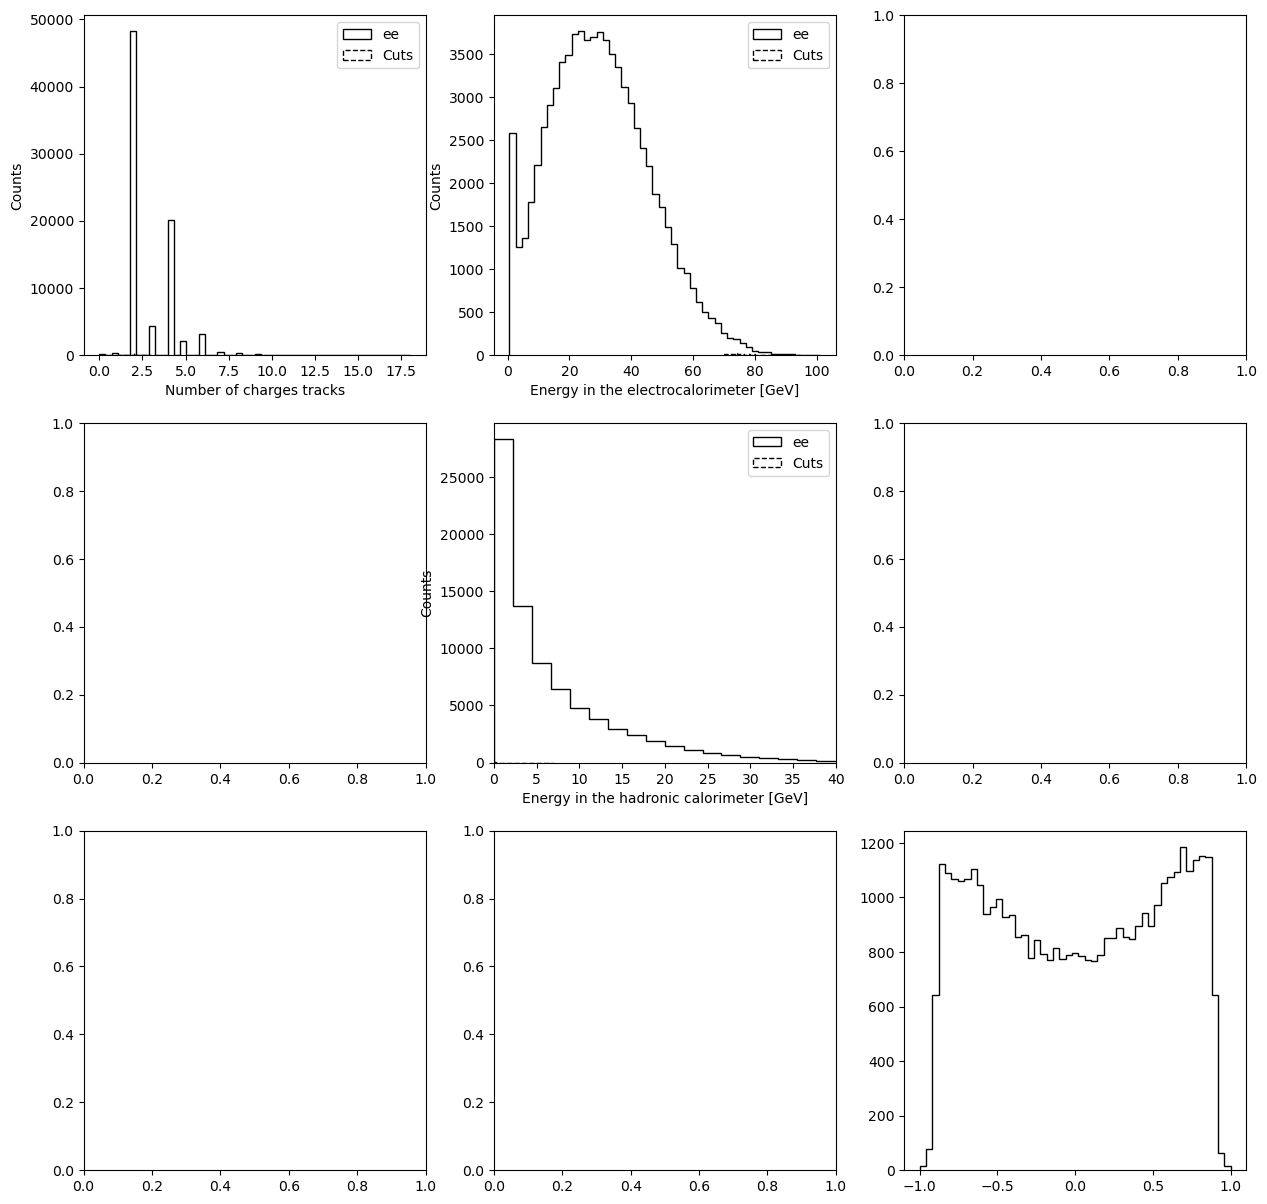

In [243]:
fig, ax = plt.subplots(nrows=3, ncols=3, figsize=(15, 15)) ## Create a grid of figures
## Each axis in ax is accessed via matrix notation, e.g., ax[i,j]

ax[0,0].hist((Ncharged1), bins=50, color=('black'), label=('ee'),histtype='step')
ax[0,0].hist(Ncharged1[mask1], bins=50, color='black', linestyle='--', label='Cuts', histtype='step')
ax[0,0].set_xlabel("Number of charges tracks")
ax[0,0].set_ylabel("Counts")
ax[0,0].legend()



ax[0,1].hist((E_ecal1), bins=50, color=('black'), label=('ee'),histtype='step')
ax[0,1].hist(E_ecal1[mask1], bins=50, color='black', linestyle='--', label='Cuts', histtype='step')
ax[0,1].set_xlabel("Energy in the electrocalorimeter [GeV]")
ax[0,1].set_ylabel("Counts")
#ax[1,0].set_title(r"$\rm{e^{+}e^{-}}$ channel")
ax[0,1].legend()

ax[1,1].hist((E_hcal1), bins=50,color=('black'), label=('ee'),histtype='step')
ax[1,1].hist(E_hcal1[mask1], bins=50, color='black', linestyle='--', label='Cuts', histtype='step')
ax[1,1].set_xlabel("Energy in the hadronic calorimeter [GeV]")
ax[1,1].set_ylabel("Counts")
#ax[1,1].set_title(r"$\rm{e^{+}e^{-}}$ channel")
ax[1,1].legend()
ax[1,1].set_xlim(0,40)

ax[2,2].hist(cos_thet1, bins=np.linspace(-1,1,50),color=('black'), label=('ee'),histtype='step')
ax[2,2].hist(cos_thet[mask1], bins=np.linspace(-1,1,50), color='black', linestyle='--', label='Cuts', histtype='step')
ax[2,2].set_xlabel(r"$\cos(\theta)$")
ax[2,2].set_ylabel("Counts")
#ax[2,2].set_title(r"$\rm{e^{+}e^{-}}$ channel")
ax[2,2].legend()

ee : 0.20245 (20245/100000)
mm : 0.82592 (82592/100000)
tt : 0.62896 (62896/100000)
qq : 0.81763 (81763/100000)


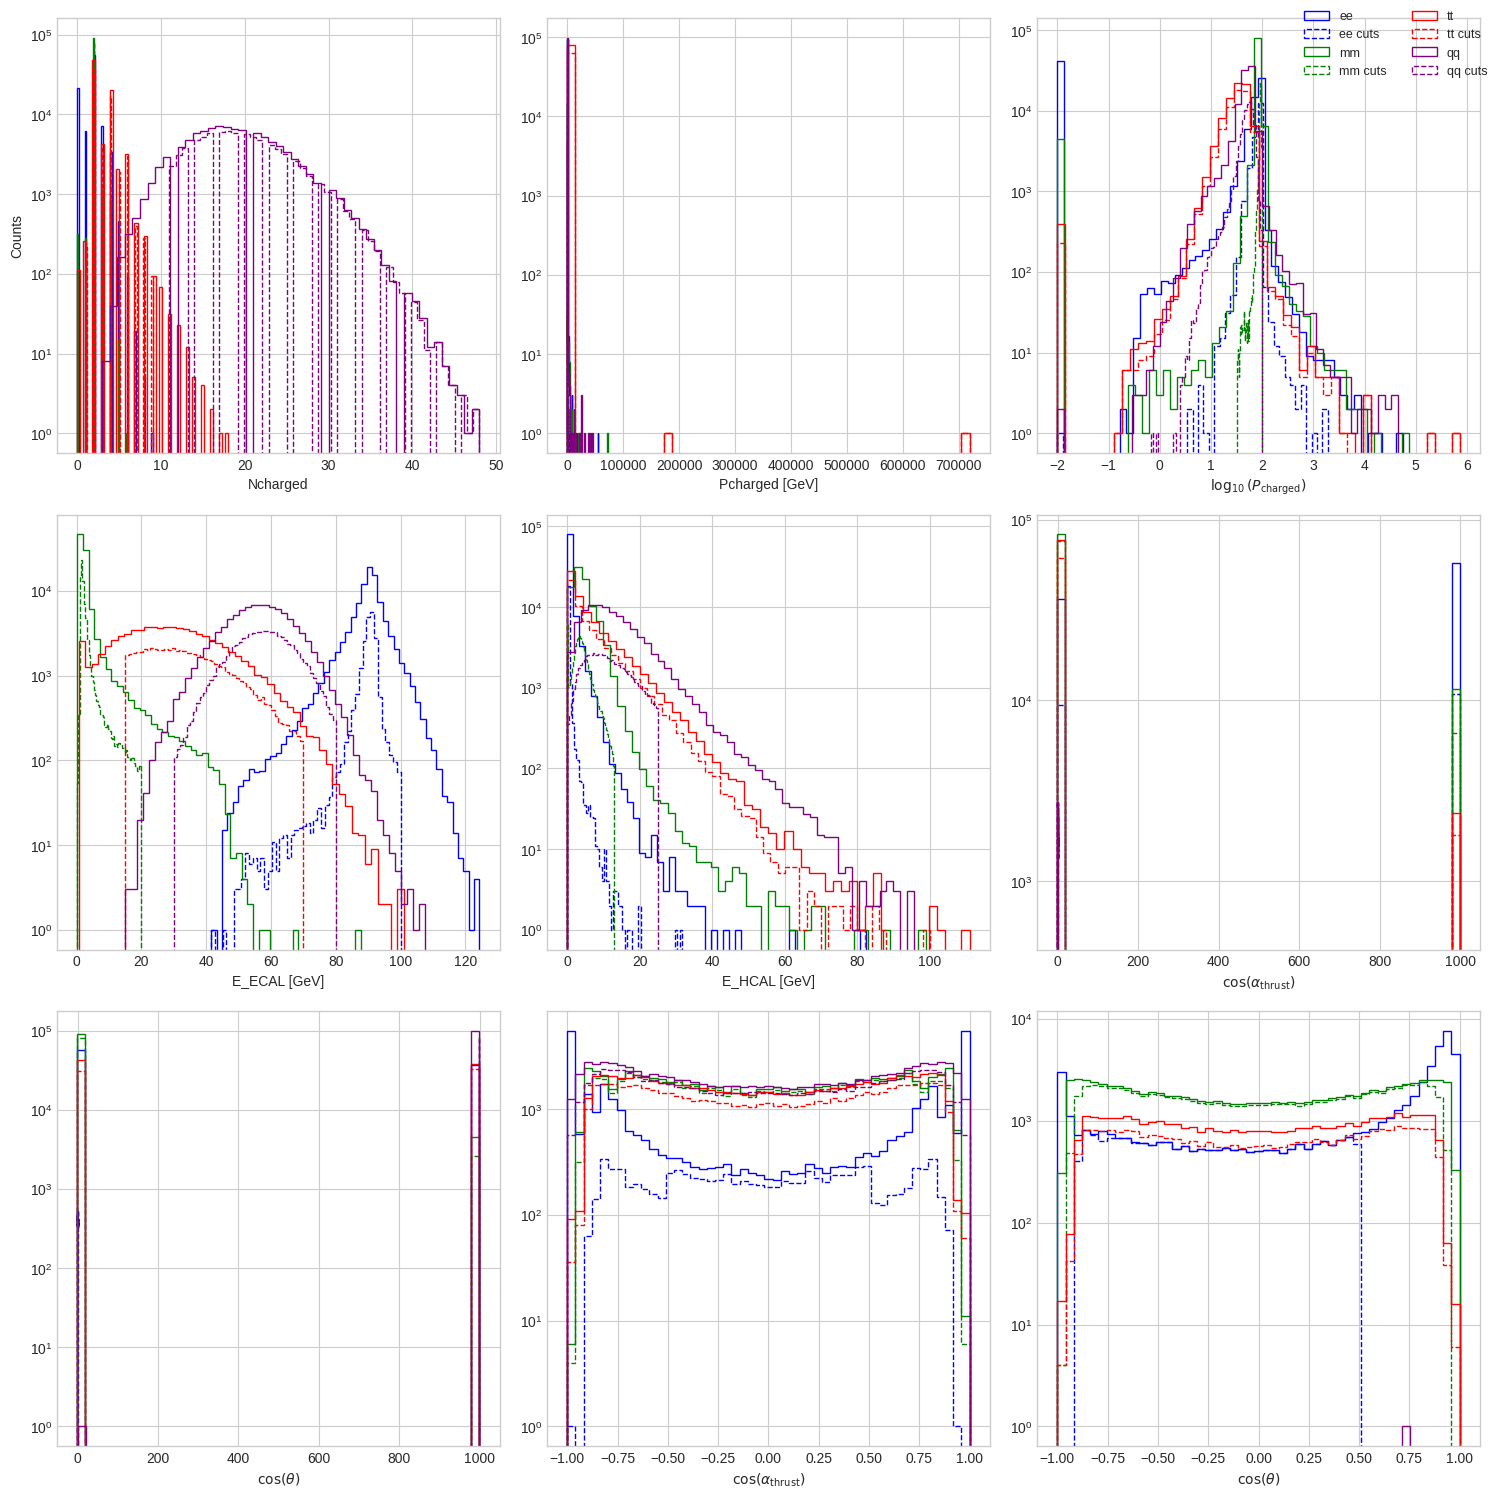

In [294]:
fig, ax = plt.subplots(nrows=3, ncols=3, figsize=(15,15))

file_paths = [
    "../Data/MC/ee.root",
    "../Data/MC/mm.root",
    "../Data/MC/tt.root",
    "../Data/MC/qq.root"
]

colors = ["blue","green","red","purple"]
labels = ["ee","mm","tt","qq"]

for i in range(len(file_paths)):

    file = uproot.open(file_paths[i])
    tree = file["h3"]

    Ncharged = np.array(tree["Ncharged"].array())
    Pcharged = np.array(tree["Pcharged"].array())
    E_ecal = np.array(tree["E_ecal"].array())
    E_hcal = np.array(tree["E_hcal"].array())
    cos_thru = np.array(tree["cos_thru"].array())
    cos_thet = np.array(tree["cos_thet"].array())

    logP = np.log10(Pcharged + 0.01)

    mask_safe = (cos_thet > -0.9) & (cos_thet < 0.5)

    masks = [

        # ee
        (
            mask_safe &
            (Ncharged > 1) &
            (Ncharged < 4) &
            (E_ecal < 100)
        ),

        # mm
        (
            (Ncharged < 4) &
            (E_ecal < 20) &
            (E_hcal < 13) &
            (logP < 2) &
            (logP > 1.5)
        ),

        # tt
        (
            (Ncharged > 0) &
            (Ncharged < 10) &
            (E_ecal > 15) &
            (E_ecal < 70)
        ),

        # qq
        (
            (Ncharged > 10) &
            (E_ecal > 30) &
            (E_ecal < 80) &
            (E_hcal < 25) &
            (logP < 2)
        )
        # ee

    ]

    selected = masks[i]

    print(
        f"{labels[i]} : "
        f"{selected.sum()/100000:.5f} "
        f"({selected.sum()}/100000)"
    )

    # Ncharged
   

    ax[0,0].hist(
        Ncharged,
        bins=50,
        histtype='step',
        color=colors[i],
        label=labels[i]
    )

    ax[0,0].hist(
        Ncharged[selected],
        bins=50,
        histtype='step',
        linestyle='--',
        color=colors[i],
        label=f"{labels[i]} cuts"
    )

    ax[0,0].set_xlabel("Ncharged")
    ax[0,0].set_ylabel("Counts")

    # Pcharged
  

    ax[0,1].hist(
        Pcharged,
        bins=50,
        histtype='step',
        color=colors[i]
    )

    ax[0,1].hist(
        Pcharged[selected],
        bins=50,
        histtype='step',
        linestyle='--',
        color=colors[i]
    )

    ax[0,1].set_xlabel("Pcharged [GeV]")

   
    # log10(Pcharged)
 

    ax[0,2].hist(
        logP,
        bins=50,
        histtype='step',
        color=colors[i]
    )

    ax[0,2].hist(
        logP[selected],
        bins=50,
        histtype='step',
        linestyle='--',
        color=colors[i]
    )

    ax[0,2].set_xlabel(r"$\log_{10}(P_{\rm charged})$")

    # ECAL


    ax[1,0].hist(
        E_ecal,
        bins=50,
        histtype='step',
        color=colors[i]
    )

    ax[1,0].hist(
        E_ecal[selected],
        bins=50,
        histtype='step',
        linestyle='--',
        color=colors[i]
    )

    ax[1,0].set_xlabel("E_ECAL [GeV]")

    # HCAL
  

    ax[1,1].hist(
        E_hcal,
        bins=50,
        histtype='step',
        color=colors[i]
    )

    ax[1,1].hist(
        E_hcal[selected],
        bins=50,
        histtype='step',
        linestyle='--',
        color=colors[i]
    )

    ax[1,1].set_xlabel("E_HCAL [GeV]")


    # cos(thrust)
  

    ax[1,2].hist(
        cos_thru,
        bins=50,
        histtype='step',
        color=colors[i]
    )

    ax[1,2].hist(
        cos_thru[selected],
        bins=50,
        histtype='step',
        linestyle='--',
        color=colors[i]
    )

    ax[1,2].set_xlabel(r"$\cos(\alpha_{\rm thrust})$")
´

    # cos(theta)
   

    ax[2,0].hist(
        cos_thet,
        bins=50,
        histtype='step',
        color=colors[i]
    )

    ax[2,0].hist(
        cos_thet[selected],
        bins=50,
        histtype='step',
        linestyle='--',
        color=colors[i]
    )

    ax[2,0].set_xlabel(r"$\cos(\theta)$")

    
    # Physical cos(thrust)
    

    ax[2,1].hist(
        cos_thru,
        bins=np.linspace(-1,1,50),
        histtype='step',
        color=colors[i]
    )

    ax[2,1].hist(
        cos_thru[selected],
        bins=np.linspace(-1,1,50),
        histtype='step',
        linestyle='--',
        color=colors[i]
    )

    ax[2,1].set_xlabel(r"$\cos(\alpha_{\rm thrust})$")

    # Physical cos(theta)


    ax[2,2].hist(
        cos_thet,
        bins=np.linspace(-1,1,50),
        histtype='step',
        color=colors[i]
    )

    ax[2,2].hist(
        cos_thet[selected],
        bins=np.linspace(-1,1,50),
        histtype='step',
        linestyle='--',
        color=colors[i]
    )

    ax[2,2].set_xlabel(r"$\cos(\theta)$")


# Formatting


for a in ax.flatten():
    a.set_yscale('log')

handles, legend_labels = ax[0,0].get_legend_handles_labels()

fig.legend(
    handles,
    legend_labels,
    loc="upper right",
    fontsize=9,
    ncol=2
)

plt.tight_layout()

plt.savefig(
    "selection_cuts_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



ee : 0.20245 (20245/100000)
Saved: ee_selection_cuts.png


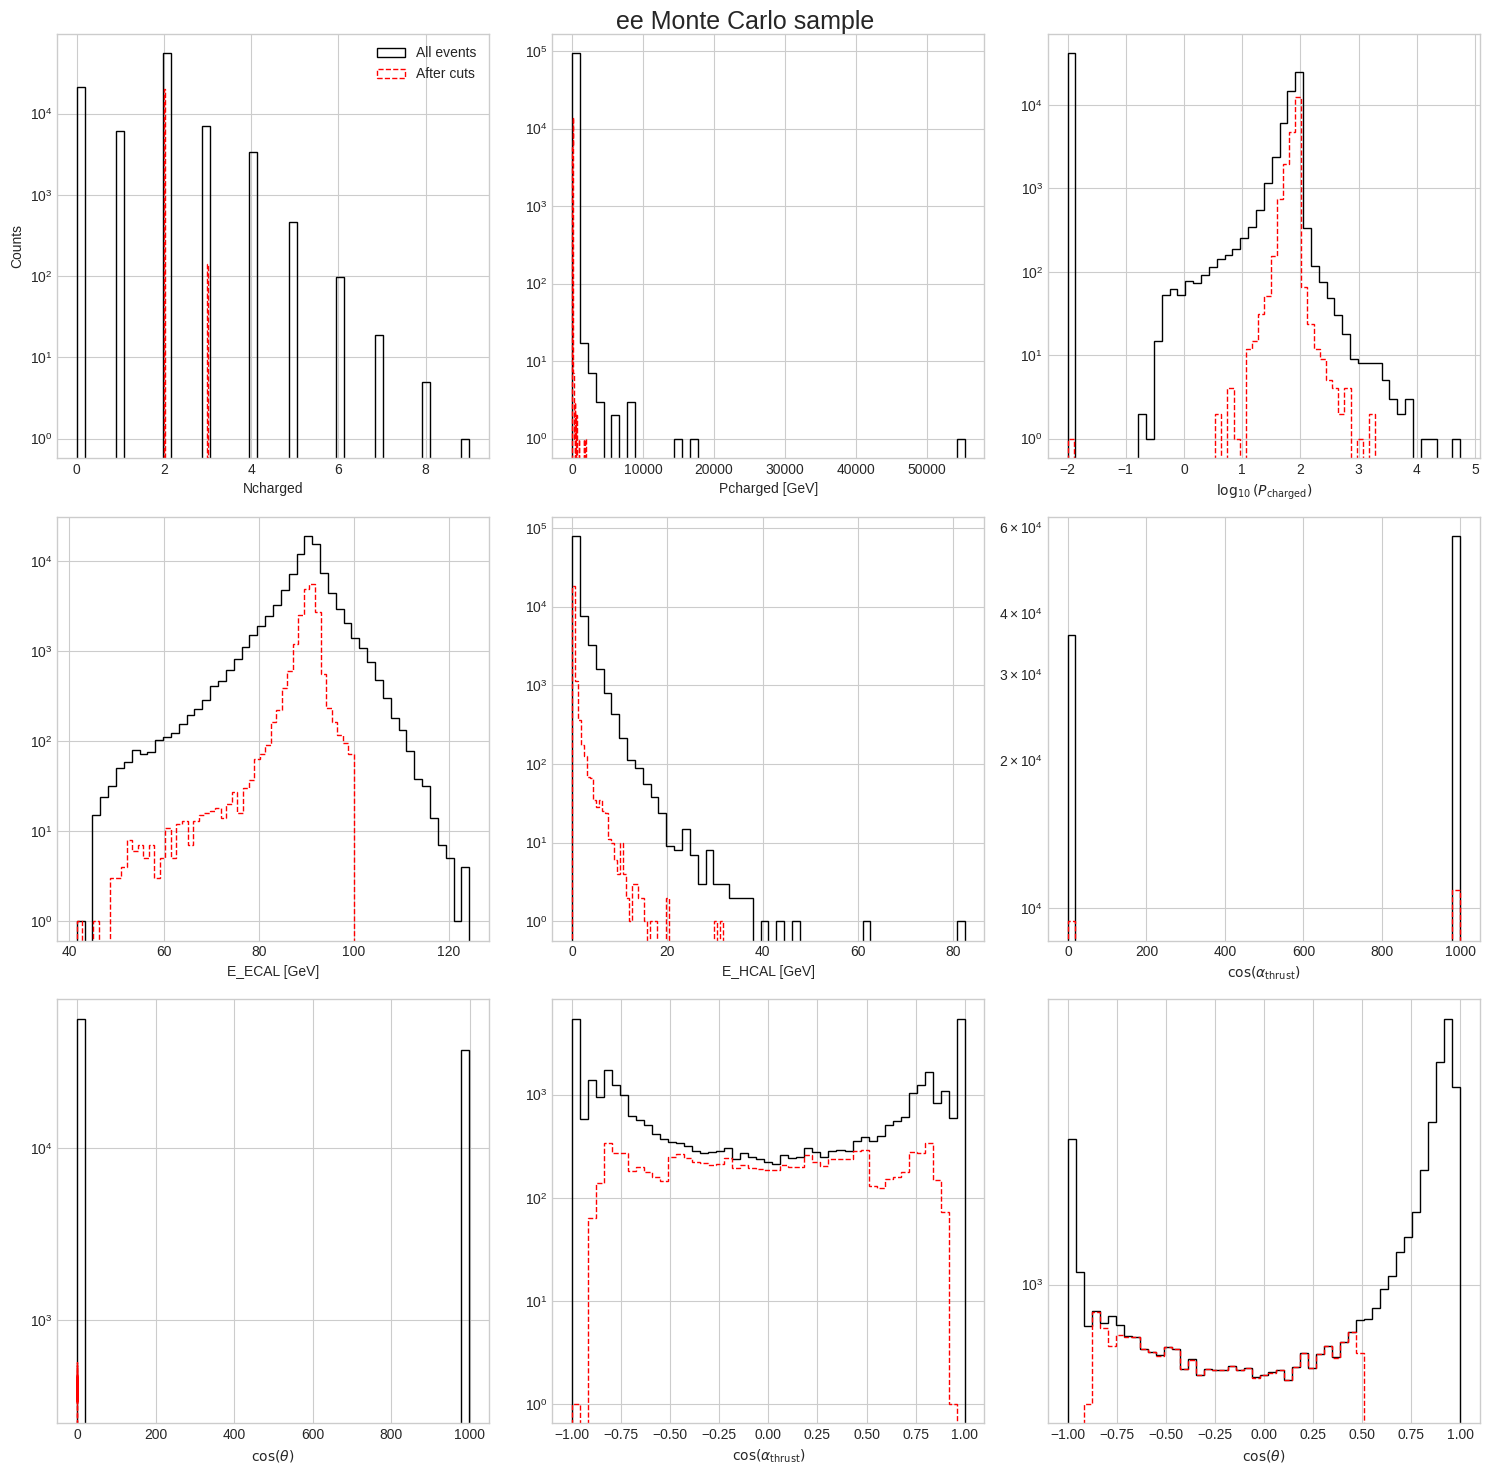

mm : 0.82592 (82592/100000)
Saved: mm_selection_cuts.png


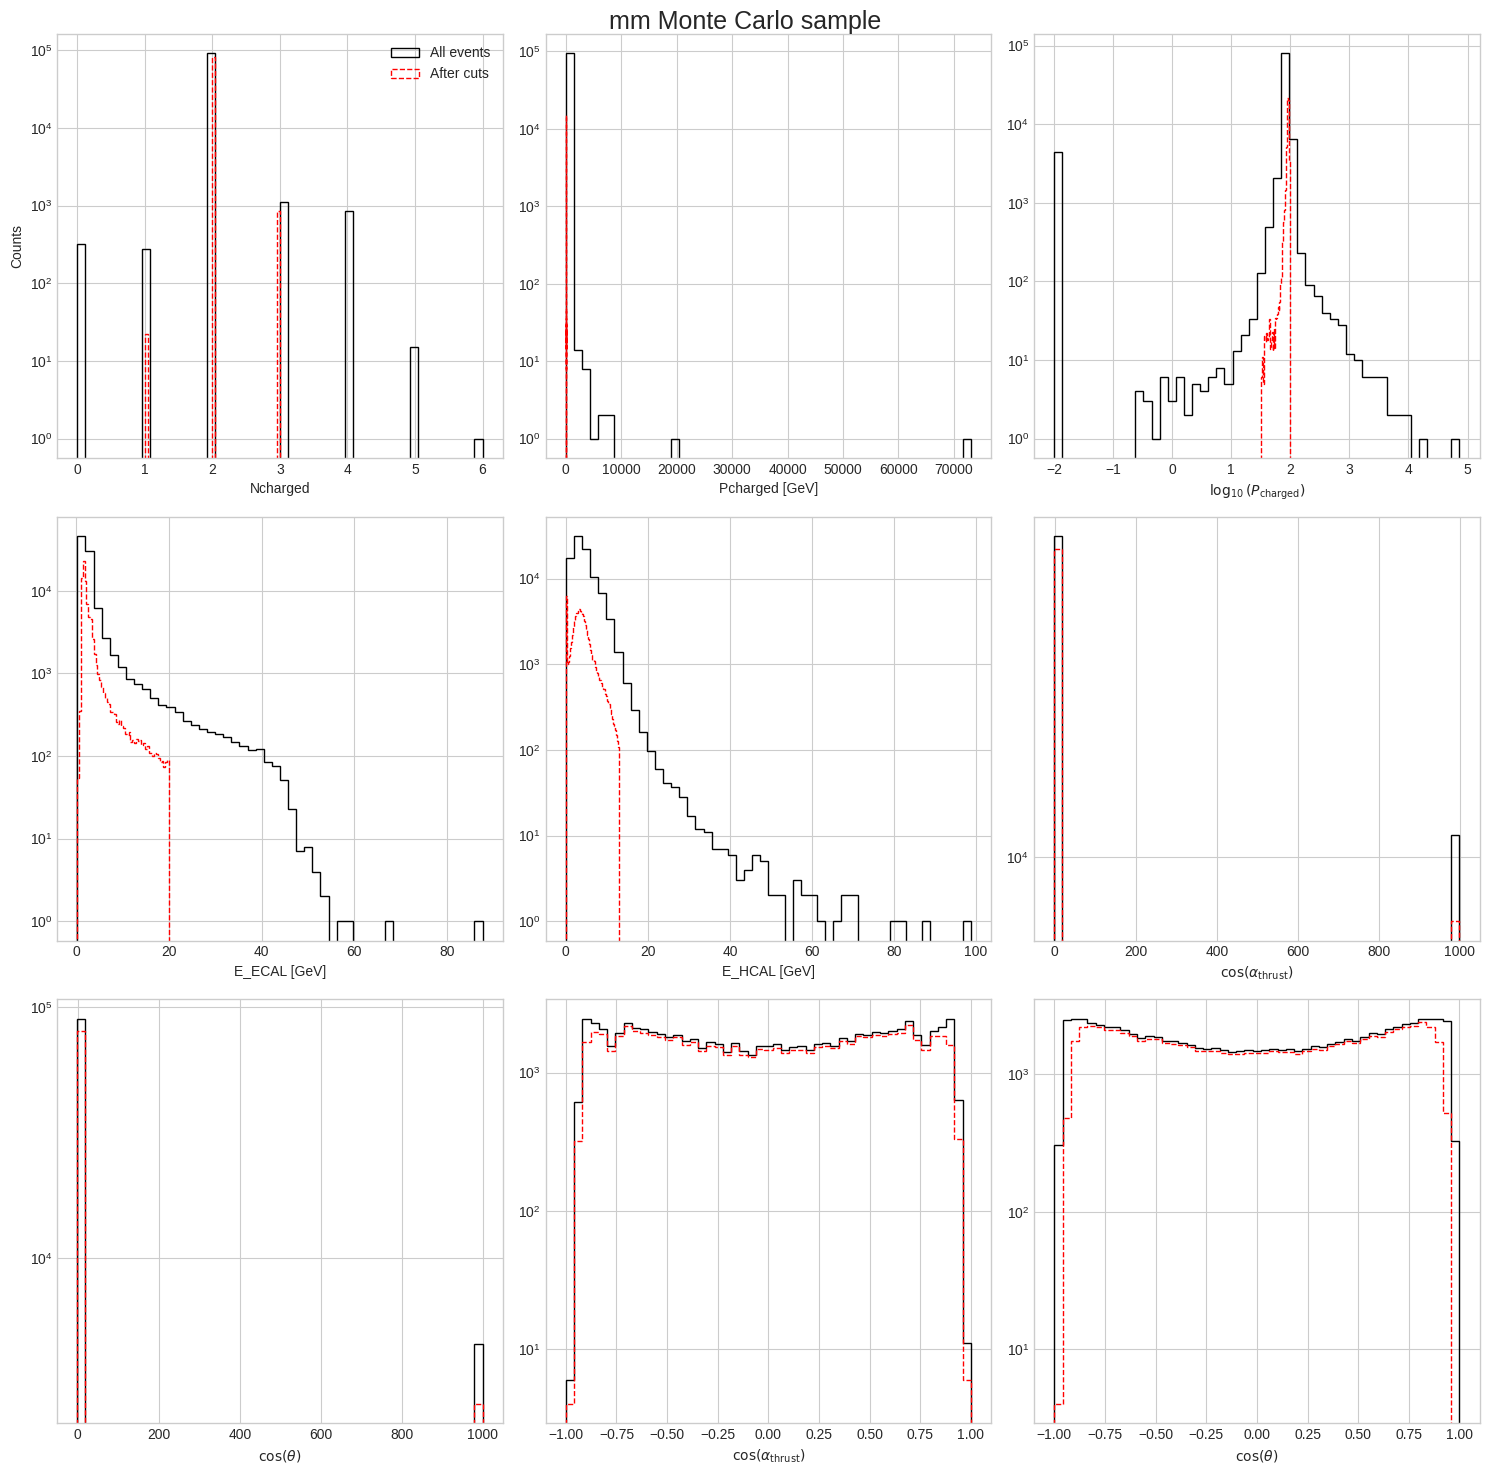

tt : 0.62896 (62896/100000)
Saved: tt_selection_cuts.png


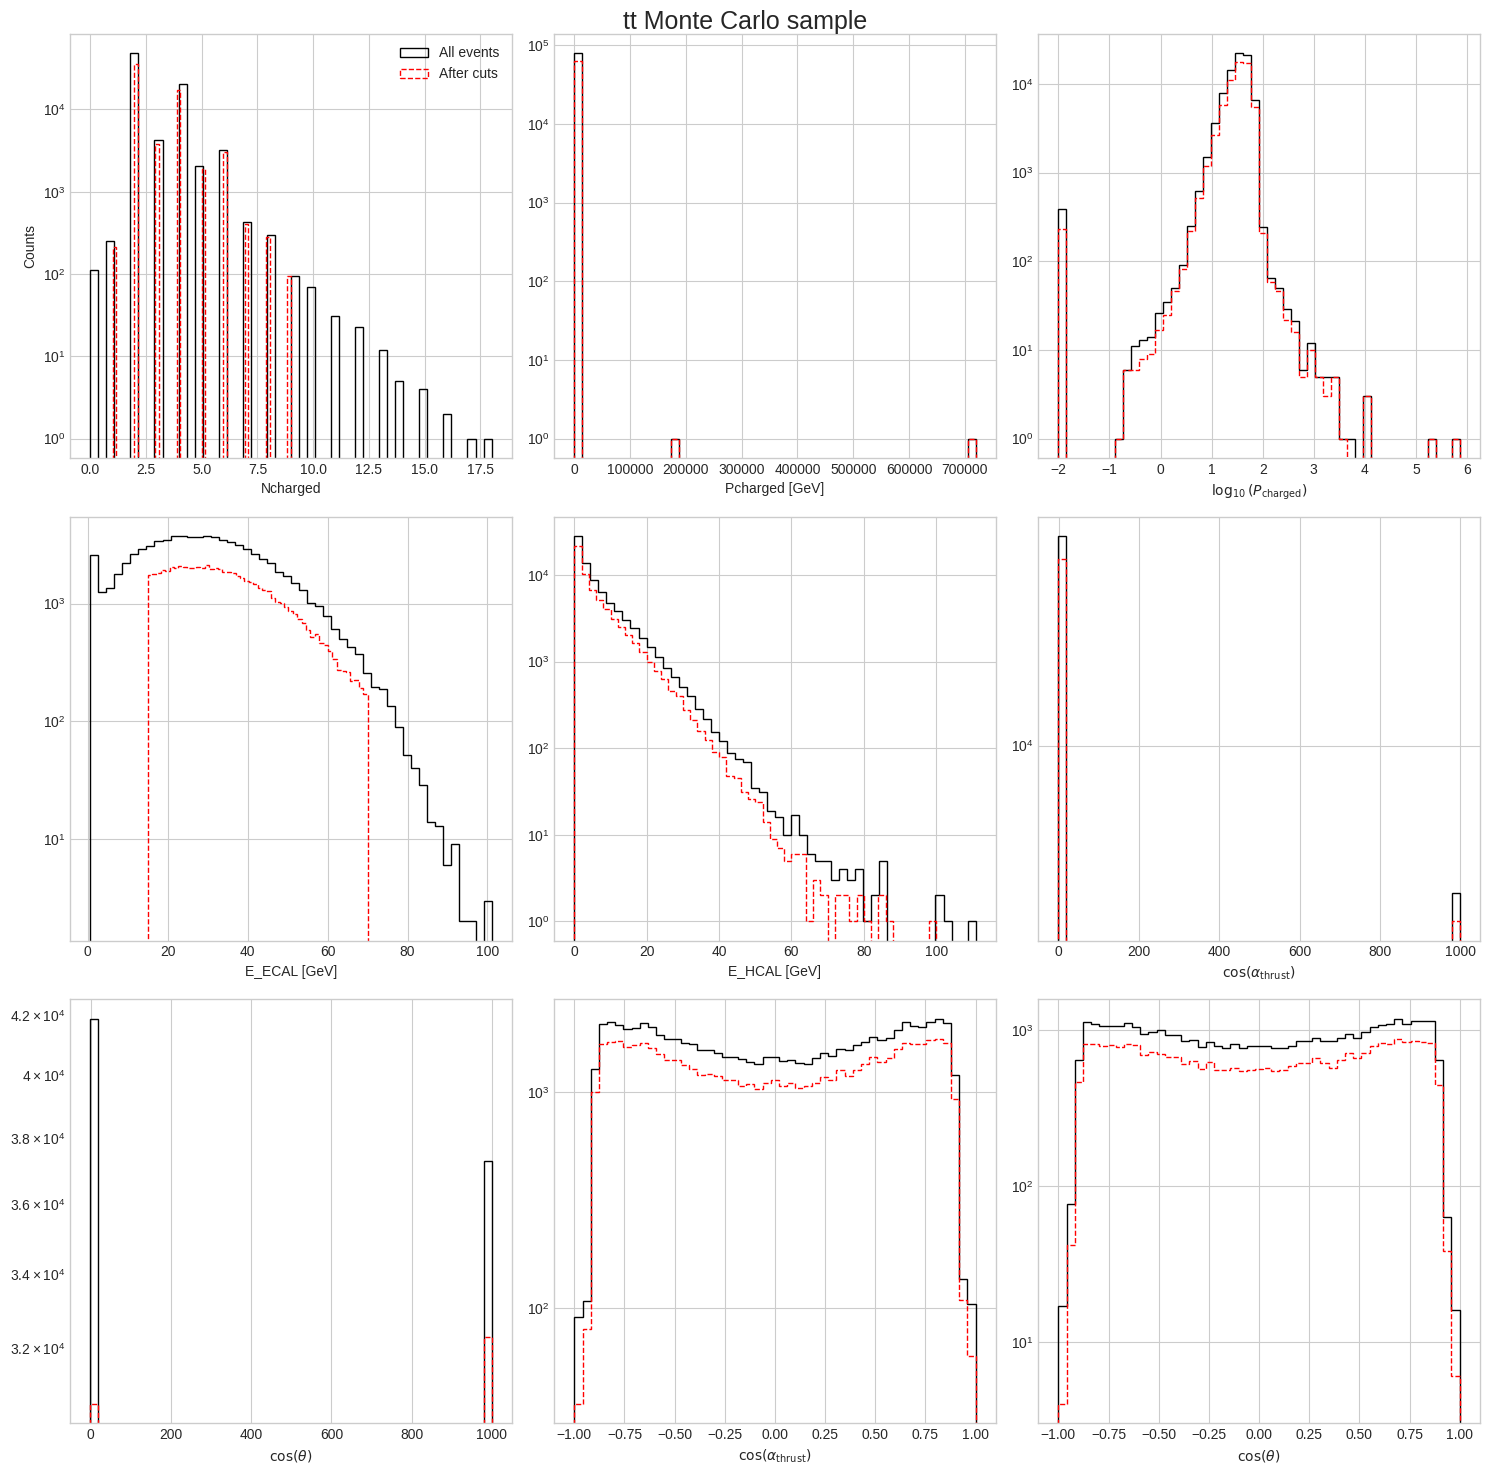

qq : 0.81763 (81763/100000)
Saved: qq_selection_cuts.png


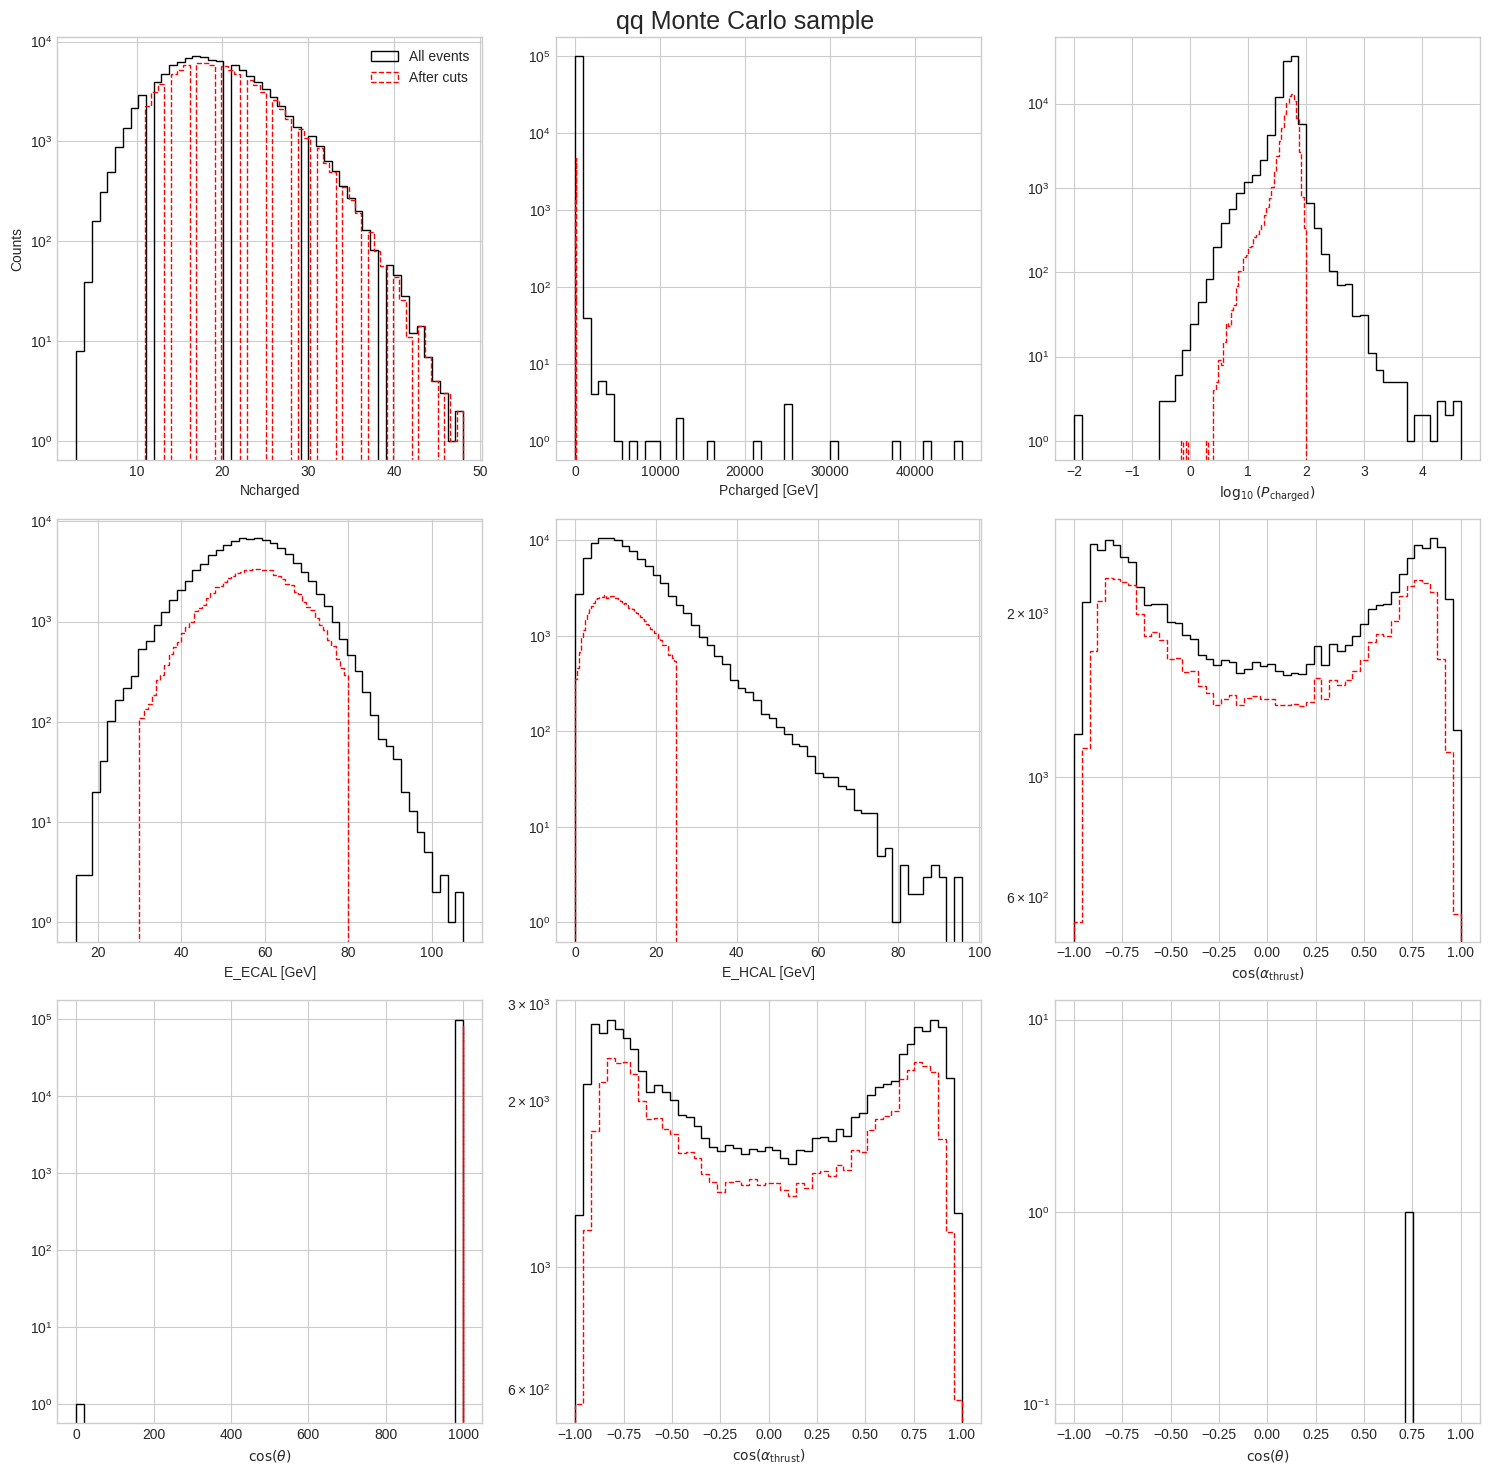

In [295]:
import uproot
import numpy as np
import matplotlib.pyplot as plt

file_paths = [
    "../Data/MC/ee.root",
    "../Data/MC/mm.root",
    "../Data/MC/tt.root",
    "../Data/MC/qq.root"
]

labels = ["ee", "mm", "tt", "qq"]

for i in range(len(file_paths)):

    # Load MC sample


    file = uproot.open(file_paths[i])
    tree = file["h3"]

    Ncharged = np.array(tree["Ncharged"].array())
    Pcharged = np.array(tree["Pcharged"].array())
    E_ecal = np.array(tree["E_ecal"].array())
    E_hcal = np.array(tree["E_hcal"].array())
    cos_thru = np.array(tree["cos_thru"].array())
    cos_thet = np.array(tree["cos_thet"].array())

    logP = np.log10(Pcharged + 0.01)

    mask_safe = (cos_thet > -0.9) & (cos_thet < 0.5)


    # Selection cuts
  

    masks = [

        # ee
        (
            mask_safe &
            (Ncharged > 1) &
            (Ncharged < 4) &
            (E_ecal < 100)
        ),

        # mm
        (
            (Ncharged < 4) &
            (E_ecal < 20) &
            (E_hcal < 13) &
            (logP < 2) &
            (logP > 1.5)
        ),

        # tt
        (
            (Ncharged > 0) &
            (Ncharged < 10) &
            (E_ecal > 15) &
            (E_ecal < 70)
        ),

        # qq
        (
            (Ncharged > 10) &
            (E_ecal > 30) &
            (E_ecal < 80) &
            (E_hcal < 25) &
            (logP < 2)
        )
    ]

    selected = masks[i]

    print(
        f"{labels[i]} : "
        f"{selected.sum()/100000:.5f} "
        f"({selected.sum()}/100000)"
    )

  
    # Create figure
    

    fig, ax = plt.subplots(3, 3, figsize=(15, 15))

   
    # Ncharged


    ax[0,0].hist(
        Ncharged,
        bins=50,
        histtype="step",
        color="black",
        label="All events"
    )

    ax[0,0].hist(
        Ncharged[selected],
        bins=50,
        histtype="step",
        linestyle="--",
        color="red",
        label="After cuts"
    )

    ax[0,0].set_xlabel("Ncharged")
    ax[0,0].set_ylabel("Counts")
    # Pcharged
    

    ax[0,1].hist(
        Pcharged,
        bins=50,
        histtype="step",
        color="black"
    )

    ax[0,1].hist(
        Pcharged[selected],
        bins=50,
        histtype="step",
        linestyle="--",
        color="red"
    )

    ax[0,1].set_xlabel("Pcharged [GeV]")


    # log10(Pcharged)
   
    ax[0,2].hist(
        logP,
        bins=50,
        histtype="step",
        color="black"
    )

    ax[0,2].hist(
        logP[selected],
        bins=50,
        histtype="step",
        linestyle="--",
        color="red"
    )

    ax[0,2].set_xlabel(r"$\log_{10}(P_{\rm charged})$")

    
    # ECAL
  

    ax[1,0].hist(
        E_ecal,
        bins=50,
        histtype="step",
        color="black"
    )

    ax[1,0].hist(
        E_ecal[selected],
        bins=50,
        histtype="step",
        linestyle="--",
        color="red"
    )

    ax[1,0].set_xlabel("E_ECAL [GeV]")

    # HCAL
  -

    ax[1,1].hist(
        E_hcal,
        bins=50,
        histtype="step",
        color="black"
    )

    ax[1,1].hist(
        E_hcal[selected],
        bins=50,
        histtype="step",
        linestyle="--",
        color="red"
    )

    ax[1,1].set_xlabel("E_HCAL [GeV]")

    
    # cos(thrust)
   

    ax[1,2].hist(
        cos_thru,
        bins=50,
        histtype="step",
        color="black"
    )

    ax[1,2].hist(
        cos_thru[selected],
        bins=50,
        histtype="step",
        linestyle="--",
        color="red"
    )

    ax[1,2].set_xlabel(r"$\cos(\alpha_{\rm thrust})$")

    # cos(theta)
   

    ax[2,0].hist(
        cos_thet,
        bins=50,
        histtype="step",
        color="black"
    )

    ax[2,0].hist(
        cos_thet[selected],
        bins=50,
        histtype="step",
        linestyle="--",
        color="red"
    )

    ax[2,0].set_xlabel(r"$\cos(\theta)$")



    ax[2,1].hist(
        cos_thru,
        bins=np.linspace(-1,1,50),
        histtype="step",
        color="black"
    )

    ax[2,1].hist(
        cos_thru[selected],
        bins=np.linspace(-1,1,50),
        histtype="step",
        linestyle="--",
        color="red"
    )

    ax[2,1].set_xlabel(r"$\cos(\alpha_{\rm thrust})$")

 

    ax[2,2].hist(
        cos_thet,
        bins=np.linspace(-1,1,50),
        histtype="step",
        color="black"
    )

    ax[2,2].hist(
        cos_thet[selected],
        bins=np.linspace(-1,1,50),
        histtype="step",
        linestyle="--",
        color="red"
    )

    ax[2,2].set_xlabel(r"$\cos(\theta)$")

  

    for axis in ax.flatten():
        axis.set_yscale("log")

    ax[0,0].legend()

    fig.suptitle(
        f"{labels[i]} Monte Carlo sample",
        fontsize=18
    )

    plt.tight_layout()



    filename = f"{labels[i]}_selection_cuts.png"

    plt.savefig(
        filename,
        dpi=300,
        bbox_inches="tight"
    )

    print(f"Saved: {filename}")

    plt.show()

In [150]:
masks[0]

array([False, False, False, ..., False, False, False])

In [137]:
print(Ntot)

98563


### Exercises

2.3.1. Define four sets of cuts, one for each channel.

2.3.2  Show the effects on the variables distributions, for every channel, with each cut.

2.3.3. Build a 4x4 matrix containing the fraction of events of MC simulations of channel $i$ surviving the cuts to select events of channel $j$.

2.3.4. Correct all the entries in the matrix for MC simulations of channel e+e- in order to keep only s-channel events using the numbers fracSChannel and totalSChannel calculated in the previous step.

### Questions

1. There are two numbers to calculate the fraction of surviving events. Either dividing by the number of events without cuts or diving by 100000 which is the initial number of MC simulations. Why are those numbers different? Which one should be used?
2. In an ideal world how do we expect this 4x4 matrix to look like?
3. How can measure which of two possible 4x4 matrices is better?

In [16]:
## Each entry here should be replaced with your results
acceptanceMatrix = np.array([[-1,-1,-1,-1],[-1,-1,-1,-1],[-1,-1,-1,-1],[-1,-1,-1,-1]]) # between 0-1
correctedAcceptanceMatrix = np.array([[-1,-1,-1,-1],[-1,-1,-1,-1],[-1,-1,-1,-1],[-1,-1,-1,-1]]) # corrected after s-t separation
totalNumberOfEvents = np.array([[-1,-1,-1,-1],[-1,-1,-1,-1],[-1,-1,-1,-1],[-1,-1,-1,-1]]) # real number of events used in the calculation

In [246]:
# Raw acceptance matrix (MC counts / 100000)

acceptanceMatrix = np.array([
    [20061,     0,    24,     0],
    [    0, 82592,  1747,     0],
    [  239,  5480, 62896,   377],
    [    0,     0,    46, 84964]
]) / 100000


# Corrected acceptance matrix
# (ee row corrected for s/t-channel separation)

correctedAcceptanceMatrix = np.array([
    [20061/25534.64025631187, 0, 24/25534.64025631187, 0],
    [0, 82592/100000, 1747/100000, 0],
    [239/100000, 5480/100000, 62896/100000, 377/100000],
    [0, 0, 46/100000, 84964/100000]
])


# Raw event counts used to build matrix

totalNumberOfEvents = np.array([
    [20061,     0,    24,     0],
    [    0, 82592,  1747,     0],
    [  239,  5480, 62896,   377],
    [    0,     0,    46, 84964]
])

print("Acceptance Matrix")
print(acceptanceMatrix)

print("\nCorrected Acceptance Matrix")
print(correctedAcceptanceMatrix)

print("\nTotal Number Of Events")
print(totalNumberOfEvents)


Acceptance Matrix
[[0.2006 0.     0.0002 0.    ]
 [0.     0.8259 0.0175 0.    ]
 [0.0024 0.0548 0.629  0.0038]
 [0.     0.     0.0005 0.8496]]

Corrected Acceptance Matrix
[[0.7856 0.     0.0009 0.    ]
 [0.     0.8259 0.0175 0.    ]
 [0.0024 0.0548 0.629  0.0038]
 [0.     0.     0.0005 0.8496]]

Total Number Of Events
[[20061     0    24     0]
 [    0 82592  1747     0]
 [  239  5480 62896   377]
 [    0     0    46 84964]]


# Part 3 - Getting the physical results

Now that we spent time learning from MC simulations how each channel works and quantitatively estimated the response of our analysis. We can apply it to real data, in which we cannot know what is the real channel that created that event.

With that we can estimate what was the initial total number of events in each channel and, thus, calculate the cross section and decay width.

## Part 3.1 - Calculate the number of real data events after cuts

From data, we have the total number of detected events for each energy bin, $k$, $N^{k}_{\rm{det}}$. We then apply each of our 4 cuts for each channel $j$, getting the number of detected events in each energy bin, $k$ and for each cut, $j$: $N^{j,k}_{\rm{det}}$

In [247]:
# Table with energy bins, don't change this

energy_bins = [44,44.5,45,45.4,45.8,46.2,46.7,47.2]

In [249]:
# Example for reading data and applying cuts

# Choose a dataset from 1, 2, 4, 5 or 6 (3 was faulty and therefore deleted)

dataset = 2

file = uproot.open(f"../Data/Real/daten_{dataset}.root")
tree = file['h33']

Ncharged = np.array(tree['Ncharged'].array())
Pcharged = np.array(tree['Pcharged'].array())
E_ecal = np.array(tree['E_ecal'].array())
E_hcal = np.array(tree['E_hcal'].array())
cos_thru = np.array(tree['cos_thru'].array())
E_lep = np.array(tree['E_lep'].array())
cos_thet = np.array(tree['cos_thet'].array())

mask_safe = mask_safe = (cos_thet > -0.9) & (cos_thet < 0.5) # If looking for ee, this cut must be kept due to the s-t contamination! For other channels this can (and maybe should) be taken out
mask = (mask_safe) & (Ncharged > 2) & (Ncharged < 10) & (cos_thru > -0.7) & (E_ecal < 100) # completely random cuts, just to show the syntax needed!

for i in range(7): # loop over energy bins
    mask_total = mask & (E_lep > energy_bins[i]) & (E_lep < energy_bins[i+1])
    print(f"Number of real data events surviving random cuts in energy bins {i}: {mask_total.sum()}")

Number of real data events surviving random cuts in energy bins 0: 1
Number of real data events surviving random cuts in energy bins 1: 2
Number of real data events surviving random cuts in energy bins 2: 2
Number of real data events surviving random cuts in energy bins 3: 29
Number of real data events surviving random cuts in energy bins 4: 8
Number of real data events surviving random cuts in energy bins 5: 4
Number of real data events surviving random cuts in energy bins 6: 0


In [253]:



energy_bins = [44,44.5,45,45.4,45.8,46.2,46.7,47.2]

dataset = 1

file = uproot.open(f"../Data/Real/daten_{dataset}.root")
tree = file["h33"]


Ncharged = np.array(tree["Ncharged"].array())
Pcharged = np.array(tree["Pcharged"].array())
E_ecal = np.array(tree["E_ecal"].array())
E_hcal = np.array(tree["E_hcal"].array())
cos_thru = np.array(tree["cos_thru"].array())
E_lep = np.array(tree["E_lep"].array())
cos_thet = np.array(tree["cos_thet"].array())


logP = np.log10(np.maximum(Pcharged, 1e-6))


mask_safe_ee = (cos_thet > -0.9) & (cos_thet < 0.5)


# ee
mask_ee = (
    mask_safe_ee &
    (Ncharged > 1) &
    (Ncharged < 4) &
    (E_ecal < 100) &
    
)

# mm
mask_mm = (
    (Ncharged < 10) &
    
    (E_ecal < 20) &
    (E_hcal < 13) &
    (logP > 1.5) &
    (logP < 2)
)

# tt
mask_tt = (
    (Ncharged > 0) &
    (Ncharged < 10) &
    (E_ecal > 15) &
    (E_ecal < 70)
)

# qq
mask_qq = (
    (Ncharged > 7) &
    (E_ecal > 30) &
    (E_ecal < 80) &
    (E_hcal < 25) &
    (logP < 2)
)


masks = [mask_ee, mask_mm, mask_tt, mask_qq]
labels = ["ee", "mm", "tt", "qq"]


N_det = np.zeros((7,4))

for k in range(7):

    energy_mask = (
        (E_lep >= energy_bins[k]) &
        (E_lep < energy_bins[k+1])
    )

    for j in range(4):

        N_det[k, j] = np.sum(masks[j] & energy_mask)


print("Detected event matrix N_det (energy bins × channels):\n")
print(N_det)

for j, name in enumerate(labels):
    print(f"\nChannel {name}:")
    for k in range(7):
        print(f"  Bin {k}: {N_det[k,j]:.0f}")

Detected event matrix N_det (energy bins × channels):

[[  131.   137.   351.  2997.]
 [  202.   252.   412.  4480.]
 [  231.   341.   499.  6314.]
 [ 2425.  3832.  6445. 77953.]
 [  355.   643.  1044. 12345.]
 [  139.   269.   481.  5475.]
 [  181.   327.   514.  6016.]]

Channel ee:
  Bin 0: 131
  Bin 1: 202
  Bin 2: 231
  Bin 3: 2425
  Bin 4: 355
  Bin 5: 139
  Bin 6: 181

Channel mm:
  Bin 0: 137
  Bin 1: 252
  Bin 2: 341
  Bin 3: 3832
  Bin 4: 643
  Bin 5: 269
  Bin 6: 327

Channel tt:
  Bin 0: 351
  Bin 1: 412
  Bin 2: 499
  Bin 3: 6445
  Bin 4: 1044
  Bin 5: 481
  Bin 6: 514

Channel qq:
  Bin 0: 2997
  Bin 1: 4480
  Bin 2: 6314
  Bin 3: 77953
  Bin 4: 12345
  Bin 5: 5475
  Bin 6: 6016


/tmp/ipykernel_4036/638820051.py:18: RuntimeWarning: invalid value encountered in log10
  logP = np.log10(np.maximum(Pcharged, 1e-6))


In [259]:
energy_bins = [44,44.5,45,45.4,45.8,46.2,46.7,47.2]

dataset = 2

file = uproot.open(f"../Data/Real/daten_{dataset}.root")
tree = file["h33"]


Ncharged = np.array(tree["Ncharged"].array())
Pcharged = np.array(tree["Pcharged"].array())
E_ecal = np.array(tree["E_ecal"].array())
E_hcal = np.array(tree["E_hcal"].array())
cos_thru = np.array(tree["cos_thru"].array())
E_lep = np.array(tree["E_lep"].array())
cos_thet = np.array(tree["cos_thet"].array())


logP = np.log10(np.maximum(Pcharged, 1e-6))


mask_safe_ee = (cos_thet > -0.9) & (cos_thet < 0.5)


# ee
mask_ee = (
    mask_safe_ee &
    (Ncharged > 1) &
    (Ncharged < 4) &
    (E_ecal < 100) &
    (E_hcal < 7)
)

# mm
mask_mm = (
    (Ncharged < 4) &
    (E_ecal < 20) &
    (E_hcal < 13) &
    (logP > 1.5) &
    (logP < 2)
)

# tt
mask_tt = (
    (Ncharged > 0) &
    (Ncharged < 10) &
    (E_ecal > 15) &
    (E_ecal < 70)
)

# qq
mask_qq = (
    (Ncharged > 10) &
    (E_ecal > 30) &
    (E_ecal < 80) &
    (E_hcal < 25) &
    (logP < 2)
)


masks = [mask_ee, mask_mm, mask_tt, mask_qq]
labels = ["ee", "mm", "tt", "qq"]


N_det = np.zeros((7,4))

for k in range(7):

    energy_mask = (
        (E_lep >= energy_bins[k]) &
        (E_lep < energy_bins[k+1])
    )

    for j in range(4):

        N_det[k, j] = np.sum(masks[j] & energy_mask)


print("Detected event matrix N_det (energy bins × channels):\n")
print(N_det)

for j, name in enumerate(labels):
    print(f"\nChannel {name}:")
    for k in range(7):
        print(f"  Bin {k}: {N_det[k,j]:.0f}")

Detected event matrix N_det (energy bins × channels):

[[  139.    68.   203.  1670.]
 [  349.   204.   384.  3953.]
 [  449.   282.   474.  5584.]
 [ 3730.  2506.  4157. 49929.]
 [  728.   566.   899. 10339.]
 [  257.   201.   367.  4092.]
 [  194.   150.   222.  2697.]]

Channel ee:
  Bin 0: 139
  Bin 1: 349
  Bin 2: 449
  Bin 3: 3730
  Bin 4: 728
  Bin 5: 257
  Bin 6: 194

Channel mm:
  Bin 0: 68
  Bin 1: 204
  Bin 2: 282
  Bin 3: 2506
  Bin 4: 566
  Bin 5: 201
  Bin 6: 150

Channel tt:
  Bin 0: 203
  Bin 1: 384
  Bin 2: 474
  Bin 3: 4157
  Bin 4: 899
  Bin 5: 367
  Bin 6: 222

Channel qq:
  Bin 0: 1670
  Bin 1: 3953
  Bin 2: 5584
  Bin 3: 49929
  Bin 4: 10339
  Bin 5: 4092
  Bin 6: 2697


/tmp/ipykernel_4036/3774800755.py:18: RuntimeWarning: invalid value encountered in log10
  logP = np.log10(np.maximum(Pcharged, 1e-6))


In [262]:

#we selected this
energy_bins = [44,44.5,45,45.4,45.8,46.2,46.7,47.2]

dataset = 4

file = uproot.open(f"../Data/Real/daten_{dataset}.root")
tree = file["h33"]


Ncharged = np.array(tree["Ncharged"].array())
Pcharged = np.array(tree["Pcharged"].array())
E_ecal = np.array(tree["E_ecal"].array())
E_hcal = np.array(tree["E_hcal"].array())
cos_thru = np.array(tree["cos_thru"].array())
E_lep = np.array(tree["E_lep"].array())
cos_thet = np.array(tree["cos_thet"].array())


logP = np.log10(np.maximum(Pcharged, 1e-6))


mask_safe_ee = (cos_thet > -0.9) & (cos_thet < 0.5)


# ee
mask_ee = (
    mask_safe_ee &
    (Ncharged > 1) &
    (Ncharged < 4) &
    (E_ecal < 100) &
    (E_hcal < 7)
)

# mm
mask_mm = (
    (Ncharged < 4) &
    (E_ecal < 20) &
    (E_hcal < 13) &
    (logP > 1.5) &
    (logP < 2)
)

# tt
mask_tt = (
    (Ncharged > 0) &
    (Ncharged < 10) &
    (E_ecal > 15) &
    (E_ecal < 70)
)

# qq
mask_qq = (
    (Ncharged > 10) &
    (E_ecal > 30) &
    (E_ecal < 80) &
    (E_hcal < 25) &
    (logP < 2)
)
masks = [mask_ee, mask_mm, mask_tt, mask_qq]
labels = ["ee", "mm", "tt", "qq"]


N_det = np.zeros((7,4))

for k in range(7):

    energy_mask = (
        (E_lep >= energy_bins[k]) &
        (E_lep < energy_bins[k+1])
    )

    for j in range(4):

        N_det[k, j] = np.sum(masks[j] & energy_mask)


print("Detected event matrix N_det (energy bins × channels):\n")
print(N_det)

for j, name in enumerate(labels):
    print(f"\nChannel {name}:")
    for k in range(7):
        print(f"  Bin {k}: {N_det[k,j]:.0f}")

Detected event matrix N_det (energy bins × channels):

[[  178.    95.   235.  2069.]
 [  483.   288.   521.  5350.]
 [  590.   386.   629.  6978.]
 [ 4075.  2784.  4532. 53615.]
 [  754.   543.   881. 10343.]
 [  321.   256.   452.  4848.]
 [  366.   284.   496.  5454.]]

Channel ee:
  Bin 0: 178
  Bin 1: 483
  Bin 2: 590
  Bin 3: 4075
  Bin 4: 754
  Bin 5: 321
  Bin 6: 366

Channel mm:
  Bin 0: 95
  Bin 1: 288
  Bin 2: 386
  Bin 3: 2784
  Bin 4: 543
  Bin 5: 256
  Bin 6: 284

Channel tt:
  Bin 0: 235
  Bin 1: 521
  Bin 2: 629
  Bin 3: 4532
  Bin 4: 881
  Bin 5: 452
  Bin 6: 496

Channel qq:
  Bin 0: 2069
  Bin 1: 5350
  Bin 2: 6978
  Bin 3: 53615
  Bin 4: 10343
  Bin 5: 4848
  Bin 6: 5454


### Exercises

3.1.1. Get the vector $N_{\rm{det}}$ with the number of real data events surviving each set of cuts

In [19]:
N_det = np.array([[178,95,235,2069]
                 [483,288,521,5350]
                 [590,386,629,6978]
                 [4075,2784,4532,53615]
                 [754,543,881,10343]
                 [321,256,452,4848]
                 [366,284,496,5454]])

## Part 3.2 - Estimate the initial number of events in each channel

$N_{\rm{det}}$ doesn't represent the real number of initial events in each channel, because some events are cut out with the cuts and there is some cross contamination. This however is estimate by our acceptance matrix, $A$. We can, therefore, obtain $N_{init}$ by:

$N^{k}_{\rm{det}} = A N^{k}_{\rm{init}} \implies N^{k}_{\rm{init}} = A^{-1} N^{k}_{\rm{det}}$


### Exercises

3.2.1. Get the vector $N_{\rm{init}}$ by applying the inverted corrected acceptance matrix on the vector calculated in the previous step

In [20]:
N_init = np.array([[-1,-1,-1,-1],
                 [-1,-1,-1,-1],
                 [-1,-1,-1,-1],
                 [-1,-1,-1,-1],
                 [-1,-1,-1,-1],
                 [-1,-1,-1,-1],
                 [-1,-1,-1,-1]])

In [274]:
N_det.T

array([[  178.,   483.,   590.,  4075.,   754.,   321.,   366.],
       [   95.,   288.,   386.,  2784.,   543.,   256.,   284.],
       [  235.,   521.,   629.,  4532.,   881.,   452.,   496.],
       [ 2069.,  5350.,  6978., 53615., 10343.,  4848.,  5454.]])

In [277]:
import numpy as np



N_det = np.array([
    [ 178.,   95.,  235.,  2069.],
    [ 483.,  288.,  521.,  5350.],
    [ 590.,  386.,  629.,  6978.],
    [4075., 2784., 4532., 53615.],
    [ 754.,  543.,  881., 10343.],
    [ 321.,  256.,  452.,  4848.],
    [ 366.,  284.,  496.,  5454.]
])


A = np.array([
    [0.7856, 0.0000, 0.0009, 0.0000],
    [0.0000, 0.8259, 0.0175, 0.0000],
    [0.0024, 0.0548, 0.6290, 0.0038],
    [0.0000, 0.0000, 0.0005, 0.8496]
])



inverse_A = np.linalg.inv(A)

print("Inverse Acceptance Matrix")
print(inverse_A)



N_init = inverse_A @ N_det 
print("\nCorrected Event Numbers N_init")
print(np.round(N_init, 2))


N_check = N_init @ A

print("\nReconstructed N_det")
print(np.round(N_check, 2))


labels = ["ee", "μμ", "ττ", "qq"]

print("\nCorrected event numbers by energy bin:")
for i in range(len(N_init)):
    print(
        f"Bin {i+1}: "
        f"ee={N_init[i,0]:8.2f}, "
        f"μμ={N_init[i,1]:8.2f}, "
        f"ττ={N_init[i,2]:8.2f}, "
        f"qq={N_init[i,3]:8.2f}"
    )

Inverse Acceptance Matrix
[[ 1.2729  0.0001 -0.0018  0.    ]
 [ 0.0001  1.213  -0.0337  0.0002]
 [-0.0049 -0.1057  1.5928 -0.0071]
 [ 0.      0.0001 -0.0009  1.177 ]]


ValueError: matmul: Input operand 1 has a mismatch in its core dimension 0, with gufunc signature (n?,k),(k,m?)->(n?,m?) (size 7 is different from 4)

In [278]:
import numpy as np

N_det = np.array([
    [178.,  95., 235., 2069.],
    [483., 288., 521., 5350.],
    [590., 386., 629., 6978.],
    [4075.,2784.,4532.,53615.],
    [754., 543., 881.,10343.],
    [321., 256., 452., 4848.],
    [366., 284., 496., 5454.]
])

A = np.array([
    [0.7856, 0.0000, 0.0009, 0.0000],
    [0.0000, 0.8259, 0.0175, 0.0000],
    [0.0024, 0.0548, 0.6290, 0.0038],
    [0.0000, 0.0000, 0.0005, 0.8496]
])

inverse_A = np.linalg.inv(A)

print("Inverse Acceptance Matrix")
print(inverse_A)

# A^{-1} * N_det^T
N_init_T = inverse_A @ N_det.T

# transpose back to 7 x 4
N_init = N_init_T.T

print("\nCorrected Event Numbers N_init")
print(np.round(N_init, 2))

# check reconstruction
N_check = (A @ N_init.T).T

print("\nReconstructed N_det")
print(np.round(N_check, 2))

labels = ["ee", "μμ", "ττ", "qq"]

print("\nCorrected event numbers by energy bin:")
for i in range(len(N_init)):
    print(
        f"Bin {i+1}: "
        f"ee={N_init[i,0]:8.2f}, "
        f"μμ={N_init[i,1]:8.2f}, "
        f"ττ={N_init[i,2]:8.2f}, "
        f"qq={N_init[i,3]:8.2f}"
    )

Inverse Acceptance Matrix
[[ 1.2729  0.0001 -0.0018  0.    ]
 [ 0.0001  1.213  -0.0337  0.0002]
 [-0.0049 -0.1057  1.5928 -0.0071]
 [ 0.      0.0001 -0.0009  1.177 ]]

Corrected Event Numbers N_init
[[  226.18   107.64   348.66  2435.06]
 [  613.95   332.63   758.94  6296.63]
 [  749.98   448.12   908.48  8212.74]
 [ 5179.65  3232.66  6522.46 63102.33]
 [  958.32   630.59  1268.5  12173.22]
 [  407.85   296.05   656.78  5705.83]
 [  465.06   328.62   719.37  6419.07]]

Reconstructed N_det
[[  178.    95.   235.  2069.]
 [  483.   288.   521.  5350.]
 [  590.   386.   629.  6978.]
 [ 4075.  2784.  4532. 53615.]
 [  754.   543.   881. 10343.]
 [  321.   256.   452.  4848.]
 [  366.   284.   496.  5454.]]

Corrected event numbers by energy bin:
Bin 1: ee=  226.18, μμ=  107.64, ττ=  348.66, qq= 2435.06
Bin 2: ee=  613.95, μμ=  332.63, ττ=  758.94, qq= 6296.63
Bin 3: ee=  749.98, μμ=  448.12, ττ=  908.48, qq= 8212.74
Bin 4: ee= 5179.65, μμ= 3232.66, ττ= 6522.46, qq=63102.33
Bin 5: ee=  958.

## Part 3.3 - Estimate the cross sections without errors

Now that we estimated the real initial number of events in each channel, we can estimate the energy-dependent cross section for each channel.

The cross-section is given by:

$\sigma_{i}(E_{k}) = \frac{N_{i,j}}{L_{k}} + \eta_{i,k}$,

where $\eta_{i,k}$ are the radiation corrections (here given to you as `radcorr_lep` and `racorr_had`)

In [264]:
# Radiation correction

radcorr_lep = np.array([0.09,0.2,0.36,0.52,0.22,-0.01,-0.08])
radcorr_had = np.array([2.0,4.3,7.7,10.8,4.7,-0.2,-1.6])

# Luminosity and energy bins for each of the given datasets

LEP_energies = {}
LEP_luminosities = {}
LEP_luminosities_error = {}

LEP_energies[1] = np.array([88.48021,89.47158,90.22720,91.23223,91.97109,92.97091,93.71841])
LEP_luminosities[1] = np.array([675.8590,543.6270,419.7760,3122.204,639.8380,479.2400,766.8380])
LEP_luminosities_error[1] = np.array([3.502185,3.179205,2.810879,7.786547,3.567344,3.121618,3.972102])

LEP_energies[2] = np.array([88.47777,89.46906,90.22324,91.23965,91.96968,92.97059,93.71714])
LEP_luminosities[2] = np.array([371.9800,488.5300,378.5461,2072.793,540.6800,369.4000,353.5000])
LEP_luminosities_error[2] = np.array([2.594937,3.009684,2.670417,6.334670,3.274401,2.737608,2.695570])

LEP_energies[4] = np.array([88.47939,89.46793,90.22266,91.22430,91.96648,92.96465,93.71712])
LEP_luminosities[4] = np.array([463.9790,667.5236,486.7641,2246.568,535.9080,450.6000,709.6980])
LEP_luminosities_error[4] = np.array([2.902361,3.521166,3.033955,6.603405,3.265110,3.027953,3.819882])

LEP_energies[5] = np.array([88.47939,89.46957,90.23120,91.23193,91.97322,92.96836,93.71712])
LEP_luminosities[5] = np.array([463.9790,472.6636,510.2150,3898.628,518.6880,624.5900,709.6980])
LEP_luminosities_error[5] = np.array([2.902361,2.964559,3.099458,8.694719,3.213012,3.564113,3.819882])

LEP_energies[6] = np.array([88.48021,89.46928,90.22604,91.24186,91.96859,92.96836,93.71685])
LEP_luminosities[6] = np.array([675.8590,800.8436,873.7021,7893.498,825.2780,624.5900,942.2280])
LEP_luminosities_error[6] = np.array([3.502185,3.855322,4.057872,12.37099,4.051215,3.564113,4.403135])

In [279]:

dataset = 4

energies = LEP_energies[dataset]
luminosities = LEP_luminosities[dataset]
luminosities_error = LEP_luminosities_error[dataset]


# Radiation corrections


radcorr_lep = np.array([0.09,0.2,0.36,0.52,0.22,-0.01,-0.08])
radcorr_had = np.array([2.0,4.3,7.7,10.8,4.7,-0.2,-1.6])





Ni_j = N_init

# Cross sections


cross_sections = np.zeros((7,4))

for k in range(7):

    # ee
    cross_sections[k,0] = (
        Ni_j[k,0] / luminosities[k]
        + radcorr_lep[k]
    )

    # μμ
    cross_sections[k,1] = (
        Ni_j[k,1] / luminosities[k]
        + radcorr_lep[k]
    )

    # ττ
    cross_sections[k,2] = (
        Ni_j[k,2] / luminosities[k]
        + radcorr_lep[k]
    )

    # hadrons
    cross_sections[k,3] = (
        Ni_j[k,3] / luminosities[k]
        + radcorr_had[k]
    )


# Print results


channels = ["e+e-", "μ+μ-", "τ+τ-", "hadrons"]

for i, channel in enumerate(channels):

    print(f"\n{channel}")
    print("-"*40)

    for k in range(7):
        print(
            f"E = {energies[k]:8.5f} GeV   "
            f"σ = {cross_sections[k,i]:10.5f}"
        )


# Full matrix


print("\nCross-section matrix:")
print(cross_sections)


e+e-
----------------------------------------
E = 88.47939 GeV   σ =    0.57748
E = 89.46793 GeV   σ =    1.11974
E = 90.22266 GeV   σ =    1.90074
E = 91.22430 GeV   σ =    2.82558
E = 91.96648 GeV   σ =    2.00822
E = 92.96465 GeV   σ =    0.89513
E = 93.71712 GeV   σ =    0.57530

μ+μ-
----------------------------------------
E = 88.47939 GeV   σ =    0.32199
E = 89.46793 GeV   σ =    0.69830
E = 90.22266 GeV   σ =    1.28061
E = 91.22430 GeV   σ =    1.95893
E = 91.96648 GeV   σ =    1.39667
E = 92.96465 GeV   σ =    0.64701
E = 93.71712 GeV   σ =    0.38305

τ+τ-
----------------------------------------
E = 88.47939 GeV   σ =    0.84145
E = 89.46793 GeV   σ =    1.33694
E = 90.22266 GeV   σ =    2.22637
E = 91.22430 GeV   σ =    3.42330
E = 91.96648 GeV   σ =    2.58701
E = 92.96465 GeV   σ =    1.44757
E = 93.71712 GeV   σ =    0.93363

hadrons
----------------------------------------
E = 88.47939 GeV   σ =    7.24821
E = 89.46793 GeV   σ =   13.73283
E = 90.22266 GeV   σ =   24

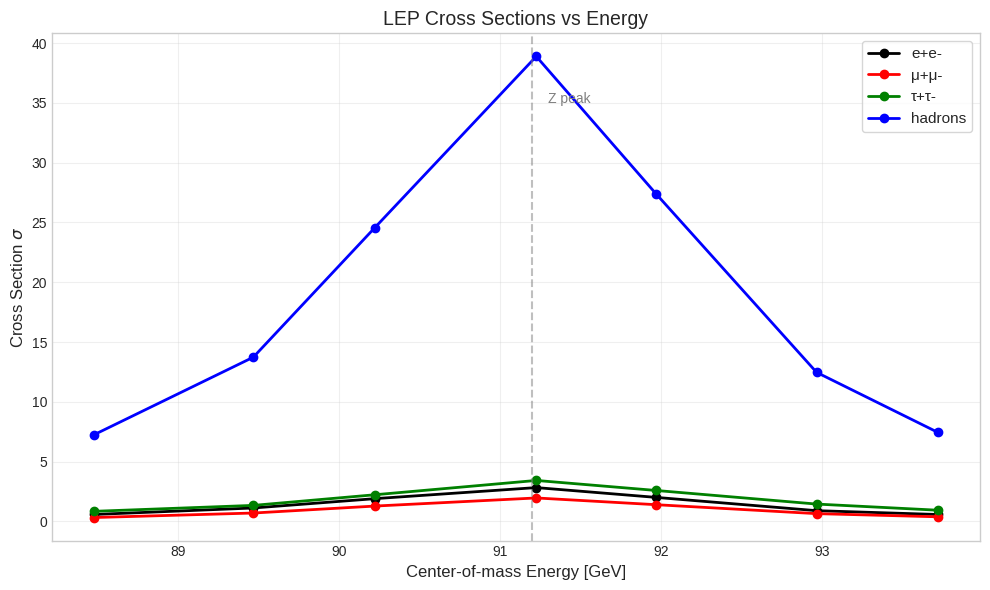

In [293]:
channels = ["e+e-", "μ+μ-", "τ+τ-", "hadrons"]
colors = ["black", "red", "green", "blue"]

plt.figure(figsize=(10,6))

# nicer background
plt.style.use("seaborn-v0_8-whitegrid")

for i in range(4):
    plt.plot(
        energies,
        cross_sections[:, i],
        marker='o',
        markersize=6,
        linewidth=2,
        color=colors[i],
        label=channels[i]
    )

# highlight Z peak region (optional but nice)
plt.axvline(91.2, color='gray', linestyle='--', alpha=0.5)
plt.text(91.3, max(cross_sections.flatten())*0.9, "Z peak", color="gray")

plt.xlabel("Center-of-mass Energy [GeV]", fontsize=12)
plt.ylabel(r"Cross Section $\sigma$", fontsize=12)

plt.title("LEP Cross Sections vs Energy", fontsize=14)

plt.legend(frameon=True, fontsize=11)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    "crosssection vs energy",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### Exercises

3.3.1. Calculate the cross section for each energy and channel for the chosen data set.

3.3.2. Plot the cross section as a function of energy for the four channels.

## Part 3.4 - Fit a Breit-Wigner function to the cross sections

Once the cross sections have been calculated, the physical quantities of the Z0-boson can be retrieved by fitting the expected Breit-Wigner cross section to the data:

$\frac{a}{\frac{4 (x-b)^2}{c^2} + \left(\frac{x}{b}\right)^2}$

### Questions

1. What physical characteristic of the Z0 does each of the free parameters, $a$, $b$ and $c$ correspond to?

### Exercises

3.4.1. Fit a Breit-Wigner function to each of the channels.

3.4.2. Plot the measured data (as in 3.3.2) together with the fitted function. Present the error in the fit function as a shaded area.

(The cells of 2.2. may be useful examples here :D)

In [23]:
def BreitWigner(x,a,b,c):
    return(a/(4./(c**2) * ((x - [b])**2) + (x/[b])**2))


$e^+e^-$
a = 2.8410 ± 0.0324
b = 91.1360 ± 0.0150 GeV
c = 2.5990 ± 0.0448 GeV

$\mu^+\mu^-$
a = 1.9708 ± 0.0173
b = 91.1756 ± 0.0116 GeV
c = 2.5098 ± 0.0332 GeV

$\tau^+\tau^-$
a = 3.3440 ± 0.0803
b = 91.2569 ± 0.0370 GeV
c = 2.9564 ± 0.1121 GeV

Hadrons
a = 38.8941 ± 0.2108
b = 91.1794 ± 0.0071 GeV
c = 2.4893 ± 0.0202 GeV


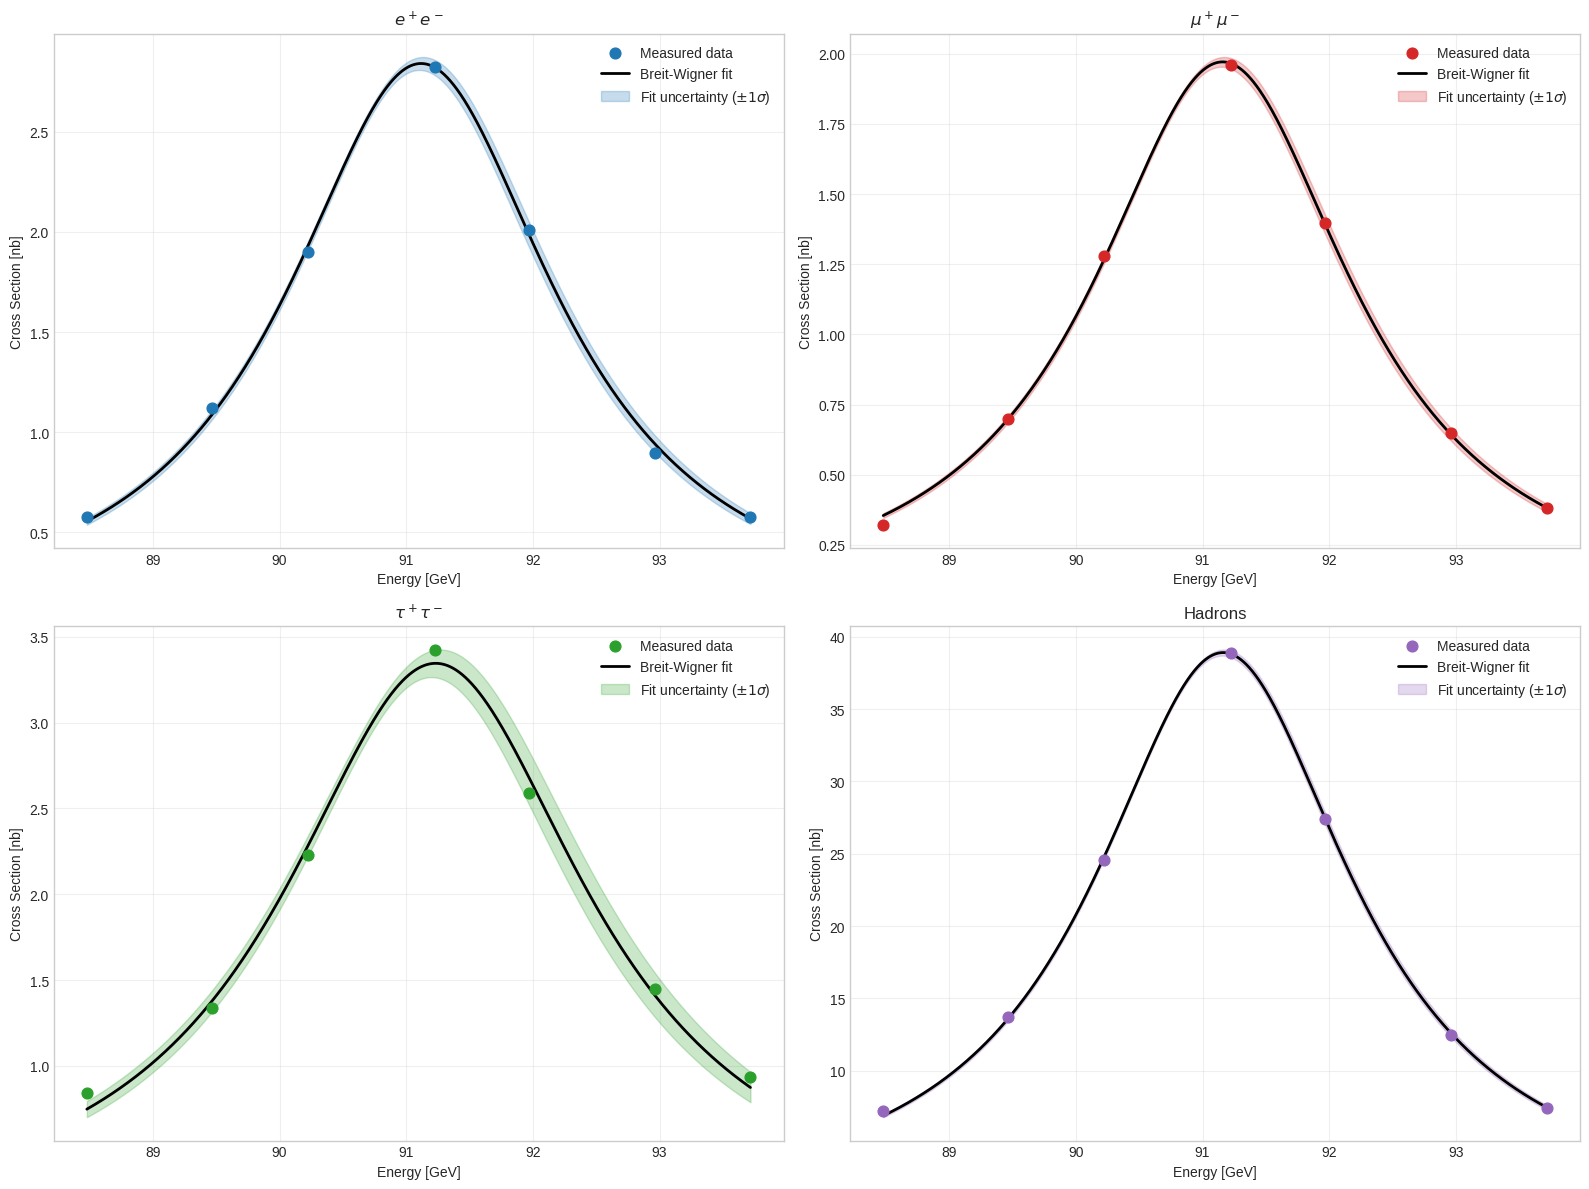

In [292]:
from scipy.optimize import curve_fit
import numpy as np
import matplotlib.pyplot as plt

# Breit-Wigner function
def breit_wigner(E, a, b, c):
    return a / ((4 * (E - b)**2) / c**2 + (E / b)**2)

channel_names = [
    r"$e^+e^-$",
    r"$\mu^+\mu^-$",
    r"$\tau^+\tau^-$",
    "Hadrons"
]

channel_colours = [
    "tab:blue",
    "tab:red",
    "tab:green",
    "tab:purple"
]

# Create figure
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

# Store fit results
fit_parameters = []
fit_errors = []

for channel_index in range(4):

    ydata = cross_sections[:, channel_index]

    # Fit Breit-Wigner
    params, covariance = curve_fit(
        breit_wigner,
        energies,
        ydata,
        p0=[np.max(ydata), 91.2, 2.5],
        bounds=([0, 80, 0], [np.inf, 100, 10])
    )

    # Parameter uncertainties
    errors = np.sqrt(np.diag(covariance))

    fit_parameters.append(params)
    fit_errors.append(errors)

    # Smooth curve
    energy_smooth = np.linspace(
        energies.min(),
        energies.max(),
        2000
    )

    fit_central = breit_wigner(
        energy_smooth,
        *params
    )

    # Same style of uncertainty as notebook example
    fit_upper = breit_wigner(
        energy_smooth,
        *(params + errors)
    )

    fit_lower = breit_wigner(
        energy_smooth,
        *(params - errors)
    )

    # Data points
    axes[channel_index].scatter(
        energies,
        ydata,
        color=channel_colours[channel_index],
        s=60,
        zorder=3,
        label="Measured data"
    )

    # Fitted curve
    axes[channel_index].plot(
        energy_smooth,
        fit_central,
        color="black",
        linewidth=2,
        label="Breit-Wigner fit"
    )

    # Error band
    axes[channel_index].fill_between(
        energy_smooth,
        fit_lower,
        fit_upper,
        color=channel_colours[channel_index],
        alpha=0.25,
        label=r"Fit uncertainty ($\pm1\sigma$)"
    )

    axes[channel_index].set_title(
        channel_names[channel_index]
    )

    axes[channel_index].set_xlabel(
        "Energy [GeV]"
    )

    axes[channel_index].set_ylabel(
        "Cross Section [nb]"
    )

    axes[channel_index].grid(alpha=0.3)
    axes[channel_index].legend()

    print("\n" + "="*50)
    print(channel_names[channel_index])

    print(
        f"a = {params[0]:.4f} ± {errors[0]:.4f}"
    )

    print(
        f"b = {params[1]:.4f} ± {errors[1]:.4f} GeV"
    )

    print(
        f"c = {params[2]:.4f} ± {errors[2]:.4f} GeV"
    )

plt.tight_layout()
plt.savefig(
    "breit wigner fit for each channel",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

## Part 3.5 - Calculate errors in the cross section data

In the previous part, the fit was done disregarding statistical uncertainties in the measured data. This means that different poins are considered equally into the fit, even tough they shouldn't. In this section we present the calculation of the errors in $\Delta \sigma_{i,k}$.

In order to calculate the final $\Delta \sigma_{i,k}$, we first need to evaluate the statistical uncertainties in each of the terms, i.e., $\Delta L_{k}$, $\Delta N^{j,k}_{\rm{det}}$ and $\Delta A_{i,j}^{-1}$.

*Luminosity*

The uncertainties in the luminosity, $\Delta L_{k}$ were given above.

*Number of measured events*

The uncertainties in the measured events is purely Poissonian, therefore: $\Delta N_{\rm{det}}^{j,k} = \sqrt{N_{\rm{det}}^{j,k}}$

*Acceptance matrix*

The uncertainties in the acceptance matrix are $\Delta A_{i,j} = \sqrt{A_{i,j} (1-A_{i,j})/10^5}$

*Inverted acceptance matrix*

The uncertainties in the INVERTED acceptance matrix are $\Delta A^{-1} = A^{-1} \Delta A A^{-1}$

Finally, via error propagation:

$\sigma_{i,k} = \frac{\Sigma_j A_{i,j}^{-1} N_{\rm{det}}^{j,k}}{L_{k}}$

$\implies \Delta \sigma_{i,k} = \sqrt{\Sigma_j \left(\Delta A^{-1}_{i,j} \frac{N_{\rm{det}}^{j,k}}{L_{k}}\right)^2 + \Sigma_j \left( \Delta N_{\rm{det}}^{j,k} \frac{A^{-1}_{i,j}}{L_{k}} \right)^2 + \Sigma_j \left( \Delta L_k \frac{A^{-1}_{i,j} N_{\rm{det}}^{j,k}}{L^2_k}\right)^2 }$

### Exercises

3.5.1. Calculate the statistical uncertainties on the cross sections for each energy and channel.

3.5.2. Plot the cross section showing the statistical uncertainties.

In [287]:

# Uncertainty propagation for cross sections


dataset = 4

energies = LEP_energies[dataset]
luminosity = LEP_luminosities[dataset]
luminosity_err = LEP_luminosities_error[dataset]

# Acceptance matrix
A = np.array([
    [7.85638638e-01, 0.00000000e+00, 9.39899672e-04, 0.00000000e+00],
    [0.00000000e+00, 8.25920000e-01, 1.74700000e-02, 0.00000000e+00],
    [2.39000000e-03, 5.48000000e-02, 2.46280000e-01, 3.77000000e-03],
    [0.00000000e+00, 0.00000000e+00, 4.60000000e-04, 8.49640000e-01]
])

# Inverse matrix
Ainv = np.linalg.inv(A)

# Detected event numbers
Ndet = np.array([
    [135, 138,  52,   2997],
    [320, 365, 110,   6683],
    [506, 679, 208,  13092],
    [6266,9792,3242,196906],
    [494, 843, 281,  16167],
    [188, 354, 132,   7054],
    [225, 386, 121,   7472]
])

# Statistical uncertainty on detected counts
dNdet = np.sqrt(Ndet)

# Binomial uncertainty on acceptance matrix
dA = np.sqrt(A * (1 - A) / 100000)

# Approximate uncertainty on inverse acceptance matrix
dAinv = Ainv @ dA @ Ainv

print("Uncertainty on detected events")
print(dNdet)

print("\nUncertainty on acceptance matrix")
print(dA)

print("\nUncertainty on inverse matrix")
print(dAinv)

# --------------------------------------------------
# Cross-section uncertainties
# --------------------------------------------------

sigma_error = np.zeros((7,4))

for energy_bin in range(7):

    for channel in range(4):

        contribution_A = np.sum(
            (dAinv[channel,:] *
             Ndet[energy_bin,:] /
             luminosity[energy_bin])**2
        )

        contribution_N = np.sum(
            (Ainv[channel,:] *
             dNdet[energy_bin,:] /
             luminosity[energy_bin])**2
        )

        contribution_L = np.sum(
            (
                Ainv[channel,:]
                * Ndet[energy_bin,:]
                * luminosity_err[energy_bin]
                / luminosity[energy_bin]**2
            )**2
        )

        sigma_error[energy_bin, channel] = np.sqrt(
            contribution_A +
            contribution_N +
            contribution_L
        )

print("\nCross-section uncertainties")
print(np.round(sigma_error, 5))

Uncertainty on detected events
[[ 11.619   11.7473   7.2111  54.7449]
 [ 17.8885  19.105   10.4881  81.7496]
 [ 22.4944  26.0576  14.4222 114.4203]
 [ 79.1581  98.9545  56.9386 443.7409]
 [ 22.2261  29.0345  16.7631 127.1495]
 [ 13.7113  18.8149  11.4891  83.9881]
 [ 15.      19.6469  11.      86.4407]]

Uncertainty on acceptance matrix
[[0.0013 0.     0.0001 0.    ]
 [0.     0.0012 0.0004 0.    ]
 [0.0002 0.0007 0.0014 0.0002]
 [0.     0.     0.0001 0.0011]]

Uncertainty on inverse matrix
[[ 0.0021 -0.      0.0005 -0.    ]
 [-0.      0.0016  0.0015 -0.    ]
 [ 0.0007  0.0017  0.022   0.0008]
 [-0.     -0.      0.0003  0.0016]]

Cross-section uncertainties
[[0.032  0.0309 0.0641 0.1471]
 [0.0343 0.035  0.0653 0.1578]
 [0.0594 0.0661 0.1247 0.3424]
 [0.0464 0.0564 0.1314 0.4059]
 [0.0533 0.067  0.1321 0.3564]
 [0.0389 0.0513 0.106  0.2531]
 [0.027  0.0339 0.0645 0.159 ]]


## Part 3.6 - Fit of the data considering errors

Finally, we can now fit the data considering the errors in the data, as it should be.

### Exercises

3.6.1. Refit the data, now including the statistical uncertainties that you calculated.

3.6.2. Plot the data with errors together with the fitted functions.

3.6.3. Calculate the $\chi^2/\rm{NDF}$ between data and model in each channel.

### Questions

1. What does the $\chi^2/\rm{NDF}$ mean?

2. What range of $\chi^2/\rm{NDF}$ denotes a good fit? What happens outside of this range?

3. How good was the fit you just got? Elaborate...


$e^+e^-$
a = 2.8437 ± 0.0443
b = 91.1250 ± 0.0206 GeV
c = 2.6086 ± 0.0505 GeV
χ² = 2.694
χ²/dof = 0.673

$\mu^+\mu^-$
a = 1.9728 ± 0.0530
b = 91.1808 ± 0.0352 GeV
c = 2.4901 ± 0.0817 GeV
χ² = 1.041
χ²/dof = 0.260

$\tau^+\tau^-$
a = 3.3101 ± 0.1091
b = 91.2750 ± 0.0415 GeV
c = 3.0313 ± 0.1165 GeV
χ² = 4.006
χ²/dof = 1.001

Hadrons
a = 38.7829 ± 0.3561
b = 91.1746 ± 0.0089 GeV
c = 2.5078 ± 0.0239 GeV
χ² = 5.385
χ²/dof = 1.346


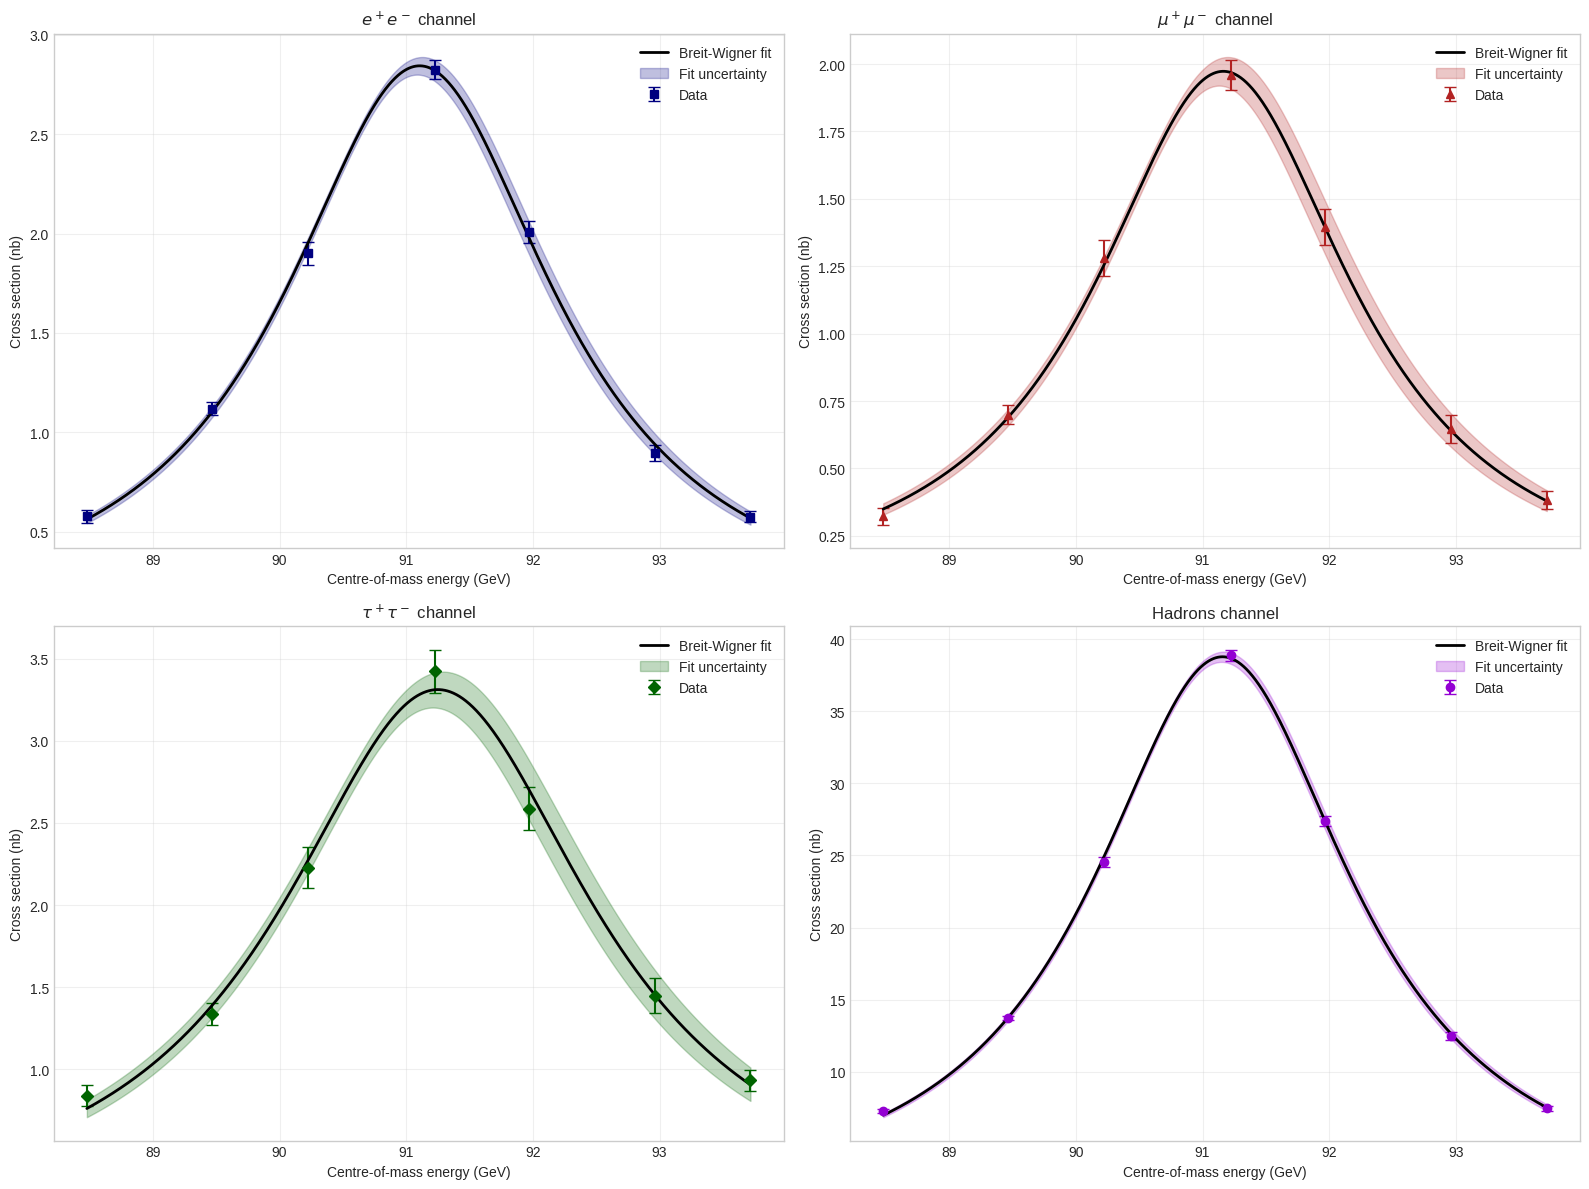

In [291]:
from scipy.optimize import curve_fit
import numpy as np
import matplotlib.pyplot as plt

# Breit-Wigner function
def breit_wigner(E, a, b, c):
    return a / ((4 * (E - b)**2) / c**2 + (E / b)**2)

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

channel_names = [r"$e^+e^-$",
                 r"$\mu^+\mu^-$",
                 r"$\tau^+\tau^-$",
                 "Hadrons"]

plot_colors = ["navy", "firebrick",
               "darkgreen", "darkviolet"]

markers = ["s", "^", "D", "o"]

for i in range(4):

    y_data = cross_sections[:, i]
    y_err = sigma_error[:, i]

    # weighted fit
    popt, pcov = curve_fit(
        breit_wigner,
        energies,
        y_data,
        sigma=y_err,
        absolute_sigma=True,
        p0=[np.max(y_data), 91.2, 2.5],
        bounds=([0, 80, 0],
                [np.inf, 100, 10])
    )

    perr = np.sqrt(np.diag(pcov))

    E_plot = np.linspace(
        energies.min(),
        energies.max(),
        1500
    )

    y_fit = breit_wigner(E_plot, *popt)

    # approximate fit uncertainty band
    y_high = breit_wigner(E_plot, *(popt + perr))
    y_low  = breit_wigner(E_plot, *(popt - perr))

    # chi-square
    chi2 = np.sum(
        ((y_data - breit_wigner(energies, *popt))
         / y_err)**2
    )

    ndof = len(energies) - len(popt)
    red_chi2 = chi2 / ndof

    # data points with error bars
    axes[i].errorbar(
        energies,
        y_data,
        yerr=y_err,
        fmt=markers[i],
        color=plot_colors[i],
        capsize=4,
        markersize=6,
        label="Data"
    )

    # fitted curve
    axes[i].plot(
        E_plot,
        y_fit,
        color="black",
        linewidth=2,
        label="Breit-Wigner fit"
    )

    # fit uncertainty band
    axes[i].fill_between(
        E_plot,
        y_low,
        y_high,
        color=plot_colors[i],
        alpha=0.25,
        label=r"Fit uncertainty"
    )

    axes[i].set_title(
        f"{channel_names[i]} channel"
    )

    axes[i].set_xlabel(
        "Centre-of-mass energy (GeV)"
    )

    axes[i].set_ylabel(
        "Cross section (nb)"
    )

    axes[i].grid(alpha=0.3)
    axes[i].legend()

    print("\n" + "="*55)
    print(channel_names[i])

    print(f"a = {popt[0]:.4f} ± {perr[0]:.4f}")
    print(f"b = {popt[1]:.4f} ± {perr[1]:.4f} GeV")
    print(f"c = {popt[2]:.4f} ± {perr[2]:.4f} GeV")

    print(f"χ² = {chi2:.3f}")
    print(f"χ²/dof = {red_chi2:.3f}")

plt.tight_layout()
plt.savefig(
    "fitted with red chi",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [289]:
print(sigma_error.shape)

(7, 4)
